# Member 1 — Philadelphia Location Intelligence & Regression
**Yelp Open Dataset · Business data · Philadelphia, Pennsylvania (PA)**

This notebook covers Member 1's responsibilities from the assignment: clean business data; explore geography, categories, ratings and competition; engineer location features; train Linear Regression, Random Forest and Gradient Boosting; evaluate MAE, RMSE and R²; and generate an interactive map plus a Streamlit location page.

**Target:** restaurant `review_count`, a cumulative Yelp popularity proxy, **not revenue**. Philadelphia is a city in Pennsylvania. Only records whose normalized city is `Philadelphia` and state is `PA` are included; nearby suburbs are excluded.

**Inputs:** the supplied `yelp_academic_dataset_business.json.zip` (or extracted business JSON). The review-file screenshot describes `review_id`, `user_id`, `business_id`, `stars`, `useful`, `funny`, `cool`, `text`, and `date`; it is not the review dataset itself. Reviews are not required for this member's scope. Nearby review features below measure cumulative counts, not recent activity.

Source: [Yelp dataset on Kaggle](https://www.kaggle.com/datasets/yelp-dataset/yelp-dataset).

**Review update:** all plots use a shared navy/teal theme; additional checks, geographic EDA, a feature dictionary and model comparisons are included below.


## Verified results - leakage and overfitting audit
The complete notebook was rerun successfully on the uploaded business ZIP. It contains **14,570 cleaned Philadelphia businesses** and **5,855 restaurants**. The original spatial split is retained: **3,585 training**, **1,111 validation** and **1,159 test** restaurants.

**Finding:** the original Random Forest showed a large log-scale train/validation gap (log R² **0.807 vs 0.234**). No direct held-out target leakage was found by the existing checks. To strengthen isolation, regression now excludes target-derived nearby review mean/sum, training-reference neighbor count and catalog-wide nearby rating mean; these remain descriptive EDA features.

**Fixes:** three-fold spatial CV on training blocks, fold-local category vocabulary and preprocessing, capped tree depths and larger leaf sizes. Revised Random Forest settings: **150 trees, max depth 6, minimum leaf size 20, max features 0.7**. Its log-MAE gap fell from **0.384 to -0.007**; log R² is now **0.358 train vs 0.206 validation**. CV still has a modest training advantage, so reduced overfitting is not a guarantee of universal generalization.

**Selection:** Random Forest remains selected by validation MAE (**58.54 reviews**); Gradient Boosting is nearly tied (**58.63**), so this is not strong evidence of a uniquely best family. Revised original-test results: **MAE 91.18**, **RMSE 221.61**, **R² 0.059**. MAE is **8.3%** lower than the median baseline. Predictive strength remains limited.

**Disclosure:** the original test set was already viewed. These test scores are a descriptive re-evaluation; they are not an untouched independent benchmark. No revised choices are selected using test metrics. All implemented leakage assertions and saved-model prediction checks passed. The Streamlit source compiles; its browser UI was not launched. No review JSON was used, and no temporal forecasting claim is made.


## Leakage and overfitting audit update
Original models are rerun to measure training and validation errors. All revised hyperparameter choices use spatial cross-validation on the original training blocks; validation selects the model family. Review-count-based neighborhood features remain in the EDA/handoff table but are excluded from regression.

**Evaluation disclosure:** the original test set was already viewed in earlier versions. Revised test results are a descriptive re-evaluation, not a newly untouched independent test. No revised parameters or feature choices are selected using test metrics. A future independent or prospective dataset is needed for an unbiased final assessment.


## 1. Setup and input paths
Place the uploaded ZIP beside the notebook, or in `data/`, and run all cells. Set `BUSINESS_PATH` if it is stored elsewhere. The notebook also detects Kaggle's `/kaggle/input` directory. Automatic downloading is disabled by default because the uploaded file is available. To download just the business file, set `DOWNLOAD_IF_MISSING=True` (Kaggle access/terms may be required).

If needed, uncomment and run the installation cell. Outputs go to `member1_philadelphia_outputs/` in your current working directory.


In [1]:
# Uncomment if dependencies are missing, then restart the kernel if needed.
# %pip install pandas numpy matplotlib 'scikit-learn>=1.3' joblib kagglehub streamlit pydeck


In [2]:
import json
import zipfile
import html
import math
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.neighbors import BallTree
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

SEED = 42
EARTH_RADIUS_KM = 6371.0088
BUSINESS_PATH = None  # Example: Path('/path/to/yelp_academic_dataset_business.json.zip')
DOWNLOAD_IF_MISSING = False
OUTPUT_DIR = Path('member1_philadelphia_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_columns', 30)

# One shared theme for every chart; no dependency on seaborn.
THEME = {'navy': '#16324F', 'teal': '#128C87', 'blue': '#387CB4',
         'gold': '#D89B38', 'muted': '#64748B', 'grid': '#E4ECF2'}
SPLIT_COLORS = {'train': THEME['blue'], 'validation': THEME['gold'], 'test': THEME['teal']}
TEAL_CMAP = LinearSegmentedColormap.from_list('philly_teal', ['#E3F4F1', THEME['teal'], THEME['navy']])
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'text.color': THEME['navy'], 'axes.labelcolor': THEME['navy'],
                     'axes.edgecolor': THEME['muted'], 'xtick.color': THEME['muted'],
                     'ytick.color': THEME['muted'], 'axes.titleweight': 'bold',
                     'axes.titlesize': 12, 'axes.titlepad': 12, 'axes.labelpad': 8,
                     'axes.prop_cycle': cycler(color=[THEME['teal'], THEME['blue'], THEME['gold'], THEME['navy']]),
                     'grid.color': THEME['grid'], 'grid.linewidth': .65,
                     'legend.frameon': False, 'savefig.dpi': 160})
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)
# Avoid nesting the wrapper if this setup cell is run twice.
if not hasattr(plt, '_member1_original_show'):
    plt._member1_original_show = plt.show
figure_counter = 0

def show_themed(*args, **kwargs):
    global figure_counter
    for number in plt.get_fignums():
        figure = plt.figure(number)
        for axis in figure.axes:
            axis.set_axisbelow(True)
            axis.grid(axis='y', alpha=.65)
        figure.tight_layout()
        figure_counter += 1
        figure.savefig(FIGURE_DIR / f'figure_{figure_counter:02d}.png', bbox_inches='tight')
        figure.savefig(FIGURE_DIR / f'figure_{figure_counter:02d}.svg', bbox_inches='tight')
    plt._member1_original_show(*args, **kwargs)
    plt.close('all')

plt.show = show_themed


In [3]:
def locate_business_file(explicit=None):
    if explicit is not None:
        path = Path(explicit).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'BUSINESS_PATH does not exist: {path}')
        return path
    names = ['yelp_academic_dataset_business.json', 'business.json',
             'yelp_academic_dataset_business.json.zip']
    for root in [Path.cwd(), Path.cwd() / 'data', Path.cwd() / 'upload', Path('/kaggle/input')]:
        if root.exists():
            for name in names:
                matches = sorted(root.rglob(name))
                if matches:
                    return matches[0]
    if DOWNLOAD_IF_MISSING:
        import kagglehub
        return Path(kagglehub.dataset_download('yelp-dataset/yelp-dataset',
                                              path='yelp_academic_dataset_business.json'))
    raise FileNotFoundError('Place the business JSON/ZIP beside this notebook or set BUSINESS_PATH.')

source_path = locate_business_file(BUSINESS_PATH)
print('Input:', source_path)


Input: /workspace/scratch/65af53800b61/upload/yelp_academic_dataset_business.json.zip


## 2. Stream the data and filter Philadelphia first
The ZIP is read directly without extracting it. Each JSON line is inspected, but only Philadelphia/PA rows are retained in memory. Invalid JSON raises a useful line-number error rather than silently dropping data.


In [4]:
def read_philadelphia(path):
    def scan(stream):
        rows, scanned = [], 0
        for line_number, line in enumerate(stream, 1):
            if not line.strip():
                continue
            scanned += 1
            try:
                row = json.loads(line)
            except (json.JSONDecodeError, UnicodeDecodeError) as exc:
                raise ValueError(f'Invalid JSON at line {line_number}') from exc
            if (str(row.get('city', '')).strip().casefold() == 'philadelphia'
                    and str(row.get('state', '')).strip().upper() == 'PA'):
                rows.append(row)
        return pd.DataFrame(rows), scanned
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as archive:
            candidates = [n for n in archive.namelist()
                          if Path(n).name in {'business.json', 'yelp_academic_dataset_business.json'}]
            if len(candidates) != 1:
                raise ValueError(f'Expected one business JSON in ZIP; found {candidates}')
            with archive.open(candidates[0]) as stream:
                return scan(stream)
    with Path(path).open('r', encoding='utf-8') as stream:
        return scan(stream)

raw_business, scanned_rows = read_philadelphia(source_path)
if raw_business.empty:
    raise ValueError('No Philadelphia, PA businesses found; check the input dataset.')
print(f'Scanned {scanned_rows:,} businesses; retained {len(raw_business):,} Philadelphia records.')
display(raw_business.head())


Scanned 150,346 businesses; retained 14,575 Philadelphia records.


,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,categories,hours
0,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,935 Race St,Philadelphia,PA,19107,39.955505,-75.155564,4.0,80,1,"{'RestaurantsDelivery': 'False', 'OutdoorSeating': 'False', 'BusinessAcceptsCreditCards': 'False', 'BusinessParking': '{'garage': False, 'street': True, 'validated': False, 'lot': False, 'valet': False}', 'BikeParking': 'True', 'RestaurantsPriceRange2': '1', 'RestaurantsTakeOut': 'True', 'ByAppointmentOnly': 'False', 'WiFi': 'u'free'', 'Alcohol': 'u'none'', 'Caters': 'True'}","Restaurants, Food, Bubble Tea, Coffee & Tea, Bakeries","{'Monday': '7:0-20:0', 'Tuesday': '7:0-20:0', 'Wednesday': '7:0-20:0', 'Thursday': '7:0-20:0', 'Friday': '7:0-21:0', 'Saturday': '7:0-21:0', 'Sunday': '7:0-21:0'}"
1,MUTTqe8uqyMdBl186RmNeA,Tuna Bar,205 Race St,Philadelphia,PA,19106,39.953949,-75.143226,4.0,245,1,"{'RestaurantsReservations': 'True', 'RestaurantsGoodForGroups': 'True', 'RestaurantsAttire': ''casual'', 'BusinessAcceptsCreditCards': 'True', 'WiFi': ''free'', 'HasTV': 'False', 'RestaurantsTakeOut': 'True', 'Ambience': '{'touristy': False, 'hipster': False, 'romantic': False, 'divey': False, 'intimate': False, 'trendy': False, 'upscale': False, 'classy': True, 'casual': False}', 'GoodForKids': 'False', 'GoodForMeal': '{'dessert': True, 'latenight': None, 'lunch': None, 'dinner': True, 'brunch': None, 'breakfast': None}', 'NoiseLevel': 'u'average'', 'RestaurantsPriceRange2': '2', 'Alcohol': ''full_bar'', 'DogsAllowed': 'False', 'HappyHour': 'True', 'RestaurantsDelivery': 'True', 'WheelchairAccessible': 'True', 'OutdoorSeating': 'True', 'RestaurantsTableService': 'True', 'BusinessParking': '{u'valet': False, u'garage': None, u'street': True, u'lot': False, u'validated': None}'}","Sushi Bars, Restaurants, Japanese","{'Tuesday': '13:30-22:0', 'Wednesday': '13:30-22:0', 'Thursday': '13:30-22:0', 'Friday': '13:30-23:0', 'Saturday': '13:30-23:0', 'Sunday': '13:30-22:0'}"
2,ROeacJQwBeh05Rqg7F6TCg,BAP,1224 South St,Philadelphia,PA,19147,39.943223,-75.162568,4.5,205,1,"{'NoiseLevel': 'u'quiet'', 'GoodForMeal': '{'dessert': False, 'latenight': False, 'lunch': True, 'dinner': True, 'brunch': False, 'breakfast': False}', 'RestaurantsGoodForGroups': 'False', 'RestaurantsTableService': 'True', 'WiFi': 'u'no'', 'GoodForKids': 'True', 'Alcohol': 'u'none'', 'RestaurantsPriceRange2': '1', 'RestaurantsAttire': 'u'casual'', 'BikeParking': 'True', 'BusinessParking': '{'garage': False, 'street': True, 'validated': False, 'lot': False, 'valet': False}', 'Caters': 'True', 'RestaurantsReservations': 'False', 'HasTV': 'True', 'BusinessAcceptsCreditCards': 'True', 'OutdoorSeating': 'None', 'Ambience': '{'touristy': False, 'hipster': False, 'romantic': False, 'divey': False, 'intimate': None, 'trendy': False, 'upscale': False, 'classy': False, 'casual': True}', 'RestaurantsDelivery': 'None', 'RestaurantsTakeOut': 'True'}","Korean, Restaurants","{'Monday': '11:30-20:30', 'Tuesday': '11:30-20:30', 'Wednesday': '11:30-20:30', 'Thursday': '11:30-20:30', 'Friday': '11:30-20:30', 'Saturday': '11:30-20:30'}"
3,QdN72BWoyFypdGJhhI5r7g,Bar One,767 S 9th St,Philadelphia,PA,19147,39.939825,-75.157447,4.0,65,0,"{'Smoking': 'u'no'', 'NoiseLevel': 'u'average'', 'Caters': 'False', 'WiFi': 'u'free'', 'RestaurantsGoodForGroups': 'True', 'Music': '{'dj': False, 'background_music': False, 'no_music': False, 'jukebox': False, 'live': False, 'video': False, 'karaoke': False}', 'OutdoorSeating': 'False', 'RestaurantsTableService': 'True', 'RestaurantsAttire': ''casual'', 'Ambience': '{'touristy': False, 'hipster': True, 'romantic': None, 'divey': False, 'intimate': False, 'trendy': None, 'upscale': False, 'classy': None, 'casual': True}', 'RestaurantsReservations': 'False', 'RestaurantsTakeOut': 'True', 'GoodForDancing': 'False', 'RestaurantsPriceRange2': '2', 'GoodForMeal': '{'dessert': False, 'latenight': False, 'lunch': False, 'dinner': False, 'brunch': True,

In [5]:
required = {'business_id', 'name', 'city', 'state', 'latitude', 'longitude',
            'stars', 'review_count', 'categories', 'is_open'}
missing = required - set(raw_business.columns)
if missing:
    raise ValueError(f'Missing required business columns: {sorted(missing)}')
quality_before = pd.DataFrame({'missing_count': raw_business.isna().sum(),
                              'missing_percent': raw_business.isna().mean().mul(100).round(2)})
display(quality_before.sort_values('missing_percent', ascending=False))

business = raw_business.copy()
audit = {'raw_philadelphia': len(business)}
business['business_id'] = business['business_id'].astype('string').str.strip()
business = business[business['business_id'].notna() & business['business_id'].ne('')].copy()
audit['missing_id_removed'] = len(raw_business) - len(business)
old_n = len(business)
business = business.drop_duplicates('business_id', keep='first').copy()
audit['duplicate_id_removed'] = old_n - len(business)
for col in ['latitude', 'longitude', 'stars', 'review_count', 'is_open']:
    business[col] = pd.to_numeric(business[col], errors='coerce')
# Missing ratings remain missing for later training-only imputation.
business.loc[~business['stars'].between(1, 5), 'stars'] = np.nan
business.loc[~business['is_open'].isin([0, 1]), 'is_open'] = np.nan
# Conservative coordinate plausibility checks around Philadelphia, not a city-boundary polygon.
valid = (business['latitude'].between(39.8, 40.2)
         & business['longitude'].between(-75.4, -74.9)
         & business['review_count'].ge(0)
         & business['review_count'].mod(1).eq(0))
audit['invalid_coordinates_or_target_removed'] = int((~valid).sum())
rejected_rows = business.loc[~valid, ['business_id', 'name', 'latitude', 'longitude', 'review_count']].copy()
rejected_rows.to_csv(OUTPUT_DIR / 'rejected_philadelphia_rows.csv', index=False)
business = business.loc[valid].reset_index(drop=True)
business['city'], business['state'] = 'Philadelphia', 'PA'
business['categories'] = business['categories'].fillna('').astype(str)
business['category_list'] = business['categories'].map(
    lambda text: sorted({c.strip() for c in text.split(',') if c.strip()}))
business['attributes'] = business.get('attributes', pd.Series(index=business.index, dtype=object)).map(
    lambda value: value if isinstance(value, dict) else {})
business['review_count'] = business['review_count'].astype(int)
business['is_restaurant'] = business['category_list'].map(lambda values: 'Restaurants' in values)
restaurants = business.loc[business['is_restaurant']].copy().reset_index(drop=True)
audit.update(clean_businesses=len(business), restaurants=len(restaurants))
assert business['business_id'].is_unique
assert business['city'].eq('Philadelphia').all() and business['state'].eq('PA').all()
if len(restaurants) < 100:
    raise ValueError('Too few restaurants for a reliable three-way regression split.')
display(pd.Series(audit, name='count').to_frame())

display(rejected_rows)
print('Rejected rows retained for inspection rather than silently discarded.')


Rejected rows retained for inspection rather than silently discarded.


,missing_count,missing_percent
hours,2783,19.09
attributes,1170,8.03
categories,9,0.06
address,0,0.00
business_id,0,0.00
name,0,0.00
postal_code,0,0.00
state,0,0.00
city,0,0.00
latitude,0,0.00


,count
raw_philadelphia,14575
missing_id_removed,0
duplicate_id_removed,0
invalid_coordinates_or_target_removed,5
clean_businesses,14570
restaurants,5855


,business_id,name,latitude,longitude,review_count
2410,Ryo0eE_Y0M0KgiYSb-hPCg,Secure Data Recovery Services,40.093063,-75.412310,5
4324,WoYoLCFZZ-eWeznm1_UxVQ,Closets by Design,40.056409,-75.651673,34
7869,pt57u94p1YsiSJhGafkcmg,Milestone Relocation Solutions,40.096919,-75.415858,39
12983,4PS-LXxGPlNM24Hmt4a4nw,Shimmer and Spice,40.247267,-75.142863,26
13355,xo4z2wCKcdK7FQ_6EYDhvA,Keep It Moving,39.943436,-74.893799,38


**Cleaning choices:** missing categories are represented as empty lists; missing attributes become empty dictionaries. Missing ratings and prices will be imputed using training data. Businesses with missing or invalid targets/coordinates are removed. Closed restaurants remain in this snapshot analysis and are marked by `is_open`; there is no historical opening/closing date. No arbitrary removal of highly reviewed restaurants is applied.


## 3. Geographic and business EDA
EDA describes the whole Philadelphia subset. Model and feature decisions are fixed below; validation data selects the model and the reused original test split is re-evaluated after selection. Categories overlap, so their counts do not sum to the business total.


,value
Philadelphia businesses,14570.000000
Philadelphia restaurants,5855.000000
Open restaurants,3527.000000
Median restaurant reviews,39.000000
Mean restaurant rating,3.556277


,stars,review_count,latitude,longitude
count,5855.000000,5855.000000,5855.000000,5855.000000
mean,3.556277,113.747908,39.974762,-75.154155
std,0.803053,241.318219,0.048125,0.051383
min,1.000000,5.000000,39.865466,-75.363647
25%,3.000000,14.000000,39.947951,-75.176409
50%,3.500000,39.000000,39.954450,-75.160402
75%,4.000000,114.000000,39.999719,-75.144594
max,5.000000,5721.000000,40.141488,-74.940729


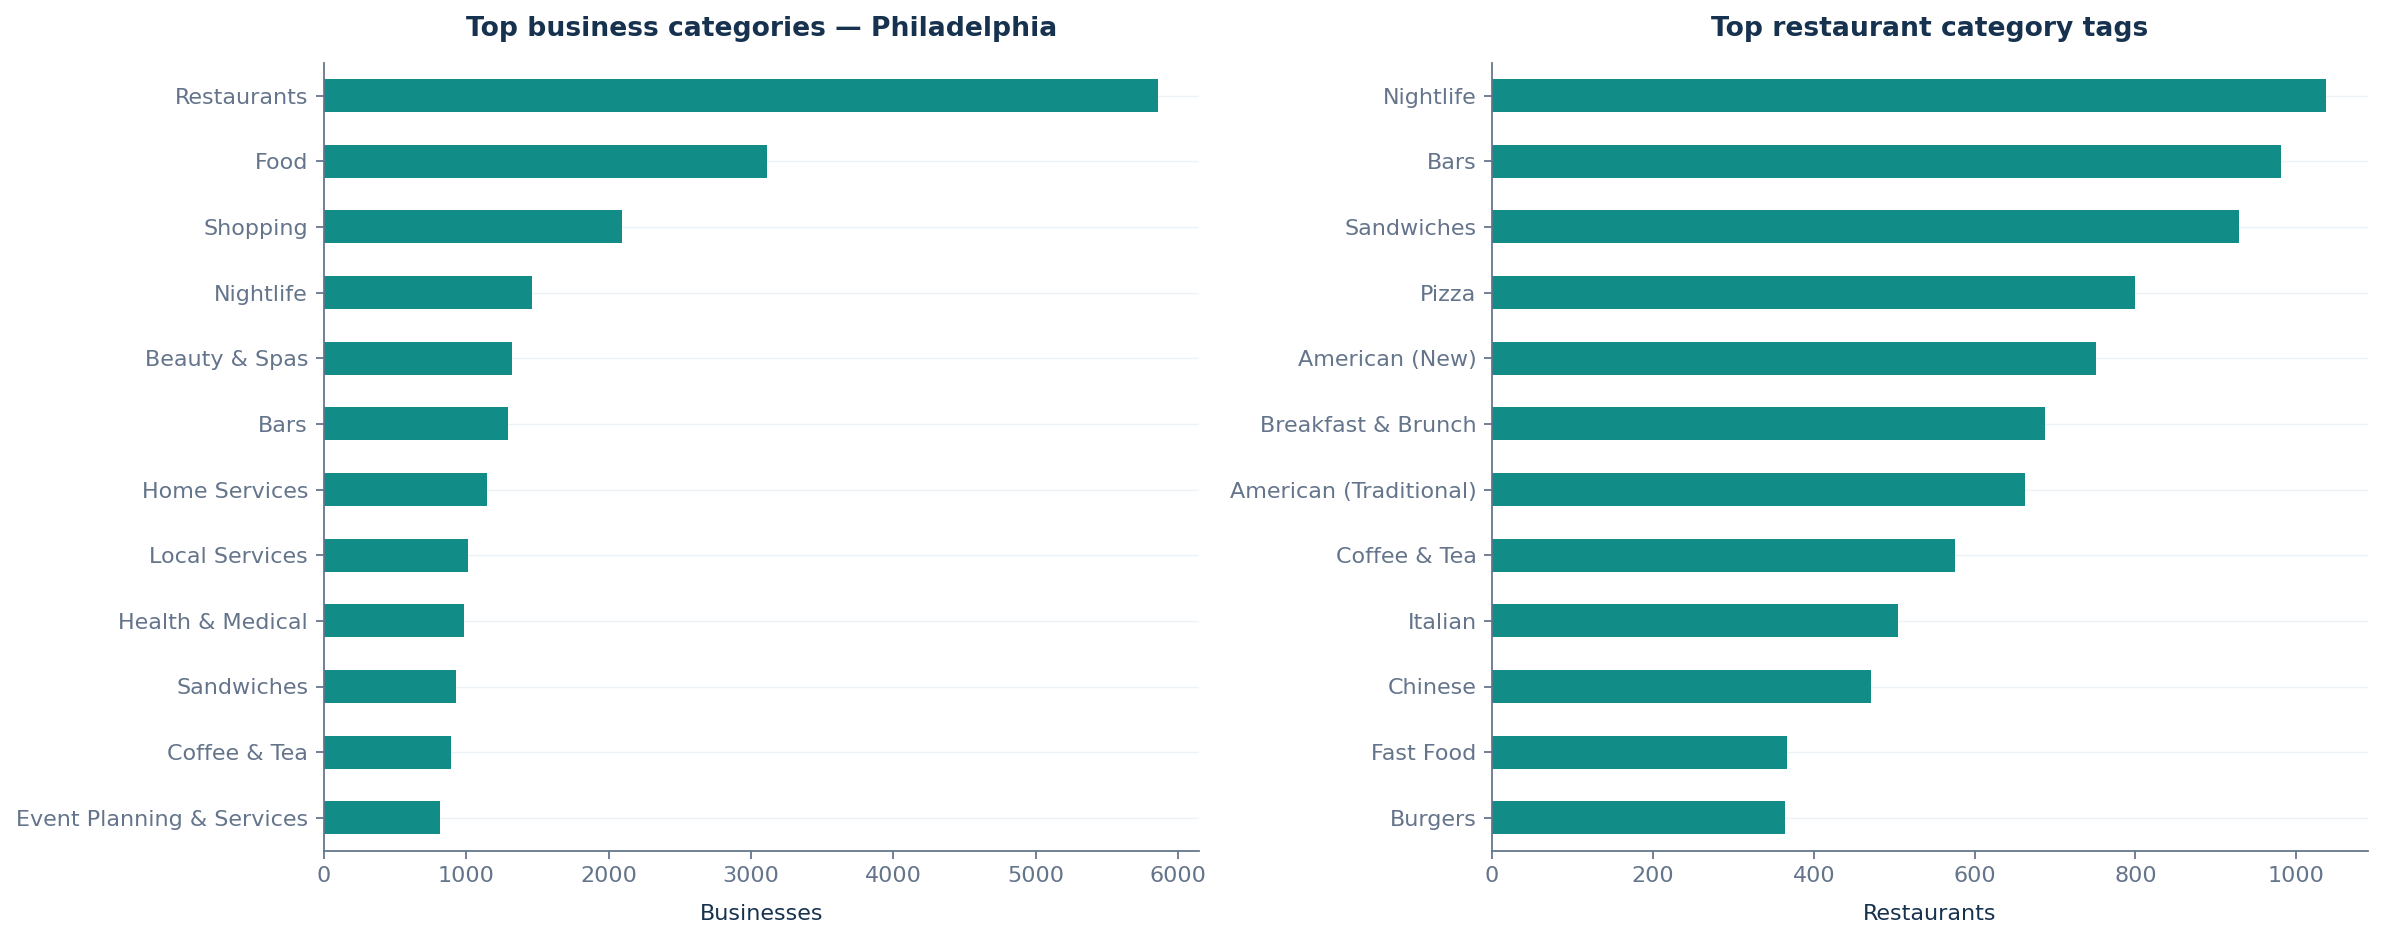

In [6]:
summary = pd.Series({
    'Philadelphia businesses': len(business), 'Philadelphia restaurants': len(restaurants),
    'Open restaurants': int(restaurants['is_open'].eq(1).sum()),
    'Median restaurant reviews': restaurants['review_count'].median(),
    'Mean restaurant rating': restaurants['stars'].mean()})
display(summary.to_frame('value'))
display(restaurants[['stars', 'review_count', 'latitude', 'longitude']].describe())

category_counts = pd.Series(Counter(c for cats in business['category_list'] for c in cats))
restaurant_categories = pd.Series(Counter(c for cats in restaurants['category_list'] for c in cats
                                         if c not in {'Restaurants', 'Food'}))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
category_counts.nlargest(12).sort_values().plot.barh(ax=axes[0], color=THEME['teal'])
axes[0].set(title='Top business categories — Philadelphia', xlabel='Businesses')
restaurant_categories.nlargest(12).sort_values().plot.barh(ax=axes[1], color=THEME['teal'])
axes[1].set(title='Top restaurant category tags', xlabel='Restaurants')
plt.tight_layout(); plt.show()


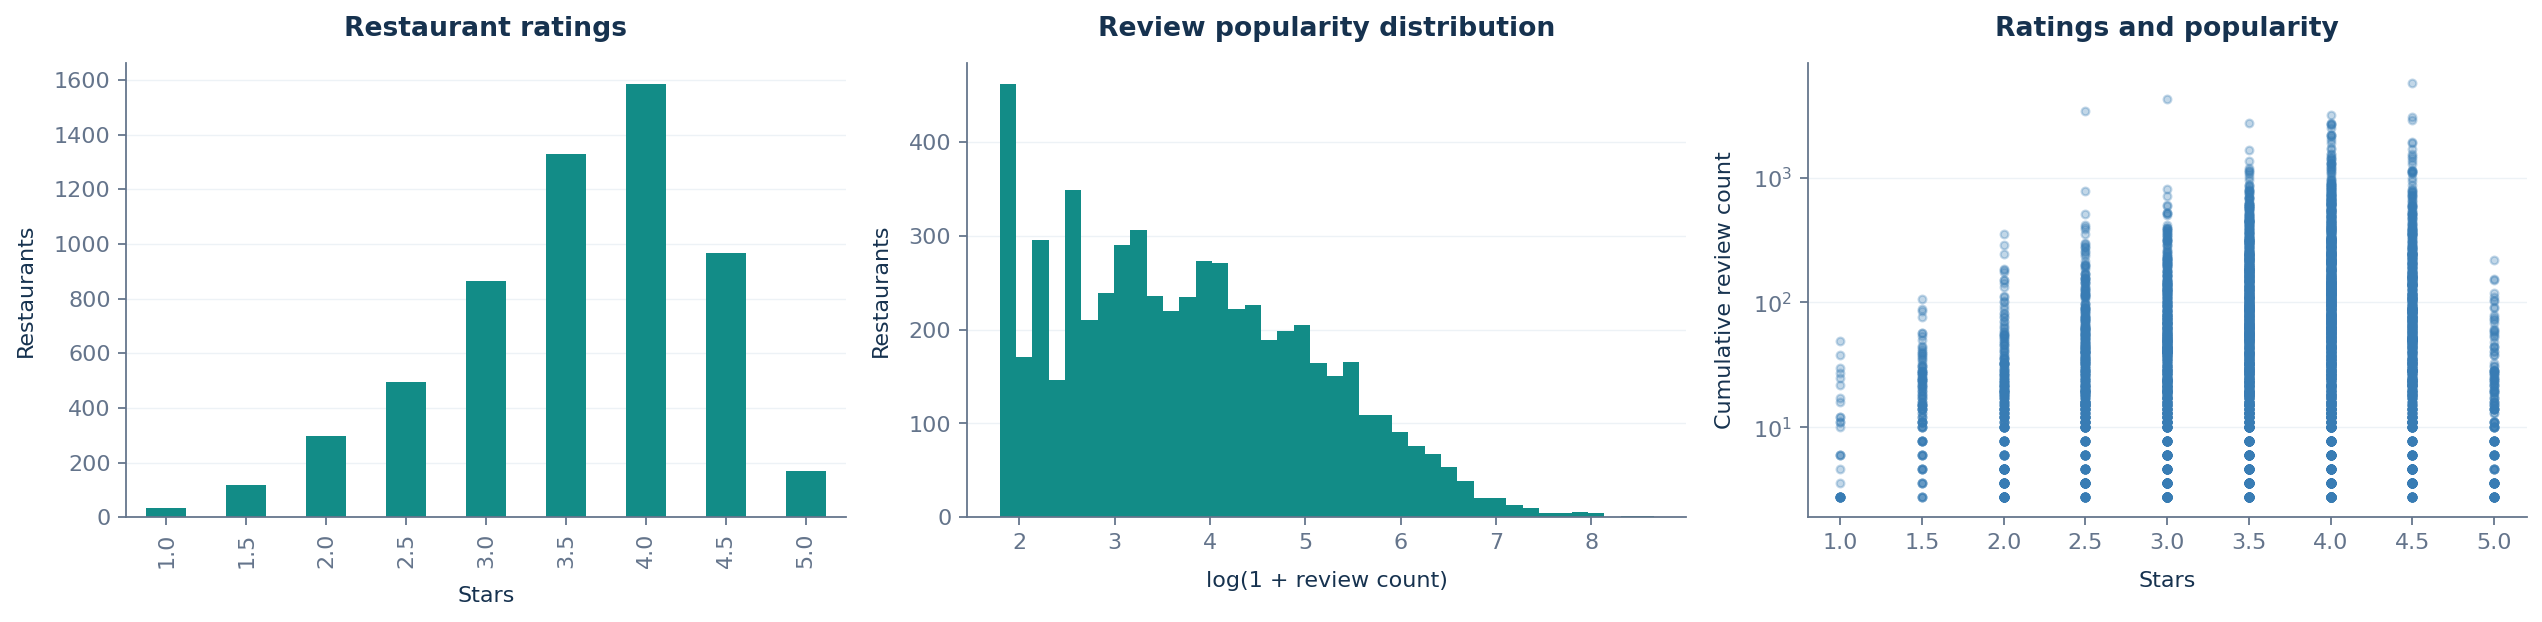

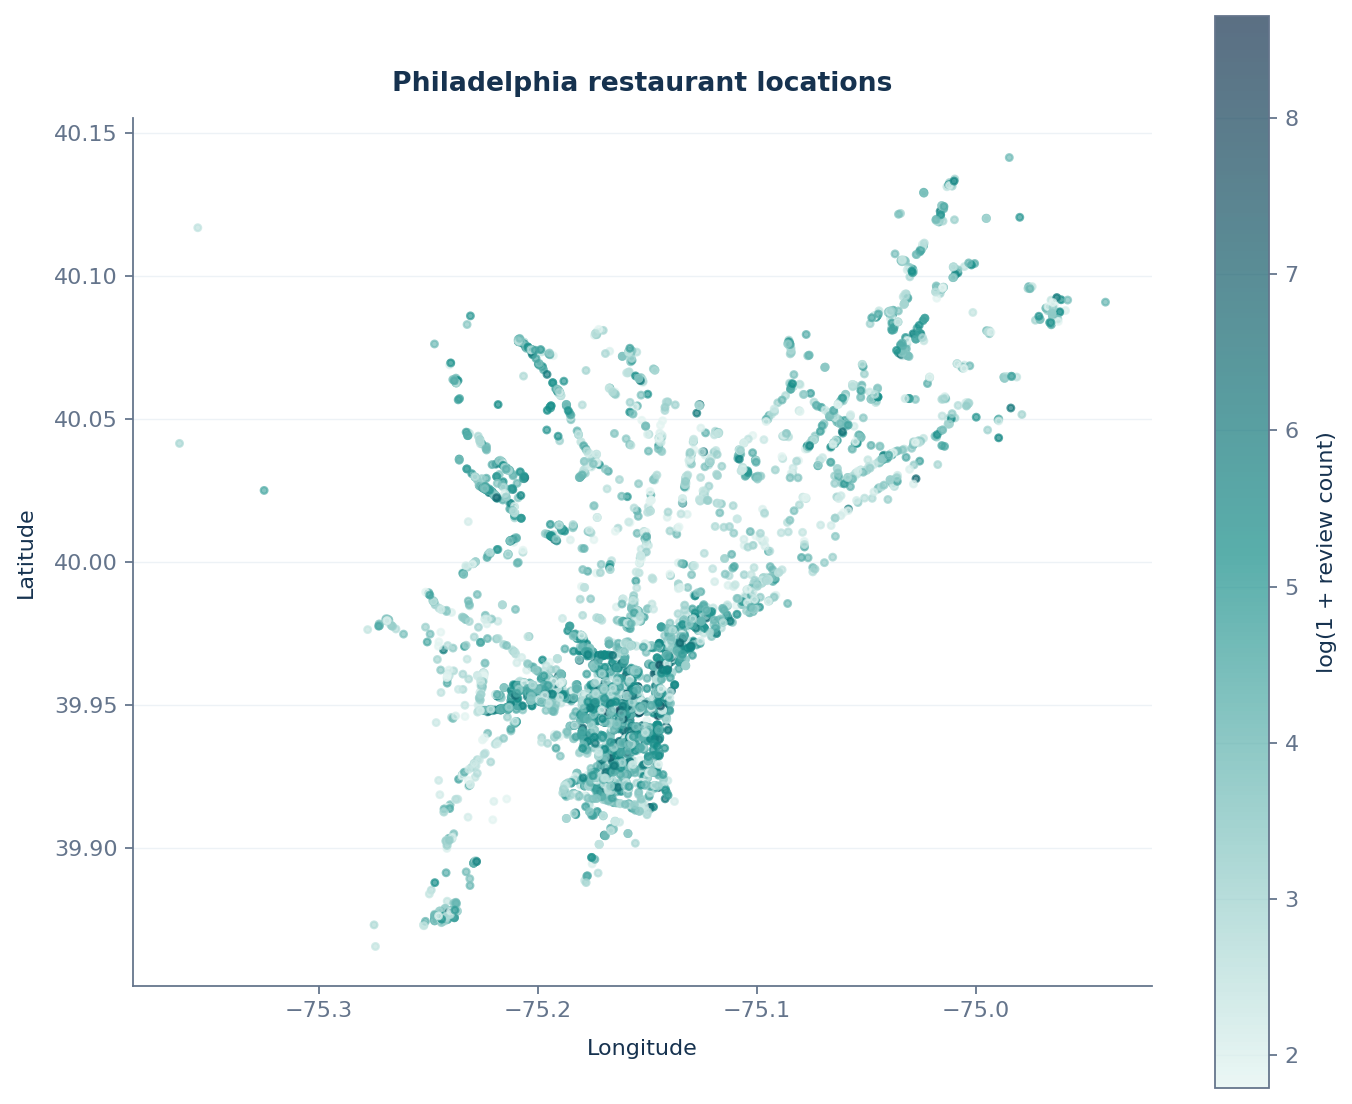

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
restaurants['stars'].dropna().value_counts().sort_index().plot.bar(ax=axes[0], color=THEME['teal'])
axes[0].set(title='Restaurant ratings', xlabel='Stars', ylabel='Restaurants')
axes[1].hist(np.log1p(restaurants['review_count']), bins=40, color=THEME['teal'])
axes[1].set(title='Review popularity distribution', xlabel='log(1 + review count)', ylabel='Restaurants')
axes[2].scatter(restaurants['stars'], restaurants['review_count'], s=12, alpha=.3, color=THEME['blue'])
axes[2].set(title='Ratings and popularity', xlabel='Stars', ylabel='Cumulative review count')
axes[2].set_yscale('symlog', linthresh=10)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
points = ax.scatter(restaurants['longitude'], restaurants['latitude'],
                    c=np.log1p(restaurants['review_count']), s=9, cmap=TEAL_CMAP, alpha=.7)
ax.set(title='Philadelphia restaurant locations', xlabel='Longitude', ylabel='Latitude')
ax.set_aspect(1 / np.cos(np.deg2rad(40)))
fig.colorbar(points, ax=ax, label='log(1 + review count)')
plt.tight_layout(); plt.show()


### Postal-code geography and restaurant status
Postal codes are a reproducible geographic grouping available in the business file; they are **not official neighborhood boundaries**. Category tags may overlap. These charts describe the dataset snapshot and do not rank profitability.


Highest restaurant concentration among postal codes: 19107
Review counts are cumulative; status does not date when a restaurant closed.


,restaurants,open_restaurants,median_reviews,mean_rating
postal_code,,,,
19107,590,323,77.0,3.67
19147,549,260,65.0,3.85
19103,481,240,69.0,3.66
19104,423,247,43.0,3.51
19106,301,139,59.0,3.61
19148,276,181,31.0,3.70
19123,232,130,53.0,3.69
19102,199,105,58.0,3.42
19130,174,104,76.5,3.70


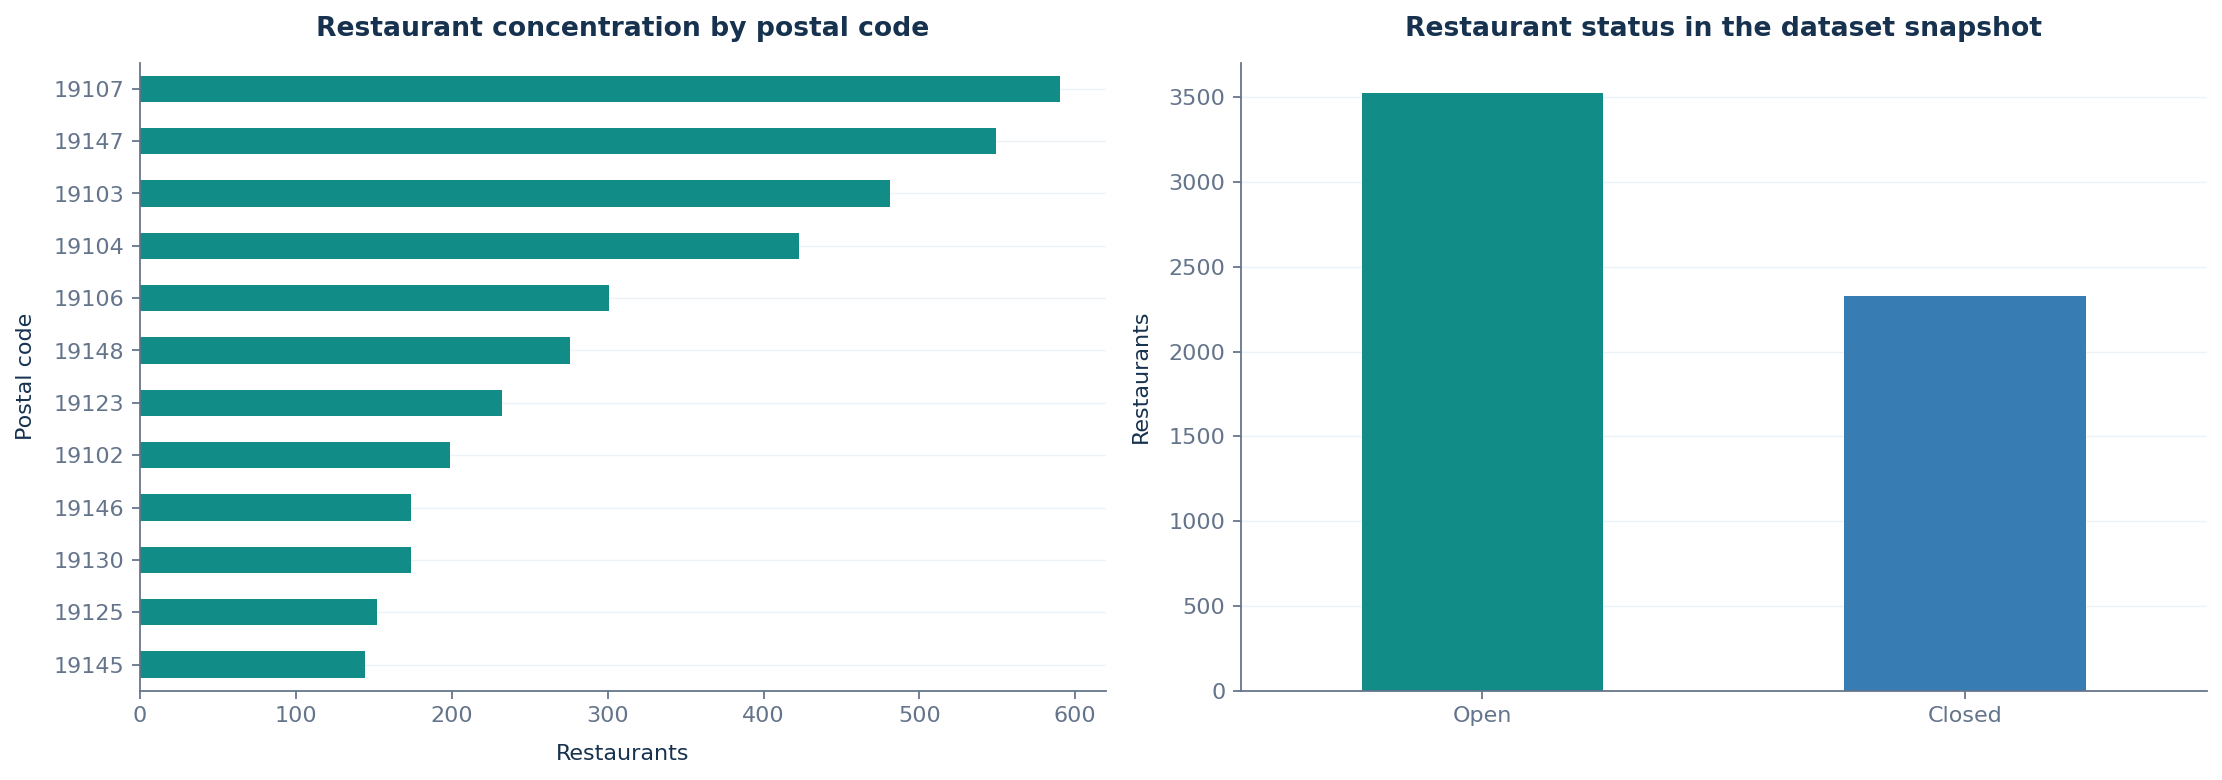

In [8]:
postal_summary = restaurants.groupby('postal_code', dropna=False).agg(
    restaurants=('business_id', 'size'), open_restaurants=('is_open', lambda s: int(s.eq(1).sum())),
    median_reviews=('review_count', 'median'), mean_rating=('stars', 'mean')).sort_values('restaurants', ascending=False)
display(postal_summary.head(15).round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
postal_summary.head(12).sort_values('restaurants')['restaurants'].plot.barh(ax=axes[0], color=THEME['teal'])
axes[0].set(title='Restaurant concentration by postal code', xlabel='Restaurants', ylabel='Postal code')
status_counts = restaurants['is_open'].map({1: 'Open', 0: 'Closed'}).fillna('Unknown').value_counts()
status_counts.plot.bar(ax=axes[1], color=[THEME['teal'], THEME['blue'], THEME['muted']], rot=0)
axes[1].set(title='Restaurant status in the dataset snapshot', xlabel='', ylabel='Restaurants')
plt.show()
print('Highest restaurant concentration among postal codes:', postal_summary.index[0])
print('Review counts are cumulative; status does not date when a restaurant closed.')


## 4. Geographic train / validation / test split
Approximately 60% / 20% / 20% of **spatial blocks** are assigned to train / validation / test, so row percentages may differ. Blocks are roughly 1 km in latitude and longitude around Philadelphia. Restaurants in the same block stay together; adjacent blocks can still be close, so this is not a buffered geographic holdout.

Review-count aggregates use **training restaurants only** for every split. A restaurant's own record is always excluded by ID. This avoids held-out target leakage. Competitor counts use all restaurant coordinates in the known Philadelphia catalog (a transductive setting); this assumes the catalog is available at scoring time.

Model tuning additionally uses three-fold GroupKFold within training blocks only. Category vocabularies, imputation, scaling and model fitting are rebuilt for each fold. The catalog coordinates are assumed known; its target values never enter predictors.


In [9]:
lat_block = np.floor((restaurants['latitude'] - 39.8) / .009).astype(int)
lon_block = np.floor((restaurants['longitude'] + 75.4) / .012).astype(int)
groups = lat_block.astype(str) + '_' + lon_block.astype(str)
if groups.nunique() < 10:
    raise ValueError('Need at least 10 spatial blocks for this split.')
splitter = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED)
train_val_idx, test_idx = next(splitter.split(restaurants, groups=groups))
splitter_val = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED + 1)
train_local, val_local = next(splitter_val.split(restaurants.iloc[train_val_idx],
                                                groups=groups.iloc[train_val_idx]))
train_idx, val_idx = train_val_idx[train_local], train_val_idx[val_local]
assert not (set(groups.iloc[train_idx]) & set(groups.iloc[val_idx]))
assert not (set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
assert not (set(groups.iloc[val_idx]) & set(groups.iloc[test_idx]))
assert min(len(train_idx), len(val_idx), len(test_idx)) >= 2
split_labels = pd.Series('train', index=restaurants.index)
split_labels.iloc[val_idx] = 'validation'
split_labels.iloc[test_idx] = 'test'
display(pd.DataFrame({'rows': split_labels.value_counts(),
                      'percent': split_labels.value_counts(normalize=True).mul(100).round(1)}))


,rows,percent
train,3585,61.2
test,1159,19.8
validation,1111,19.0


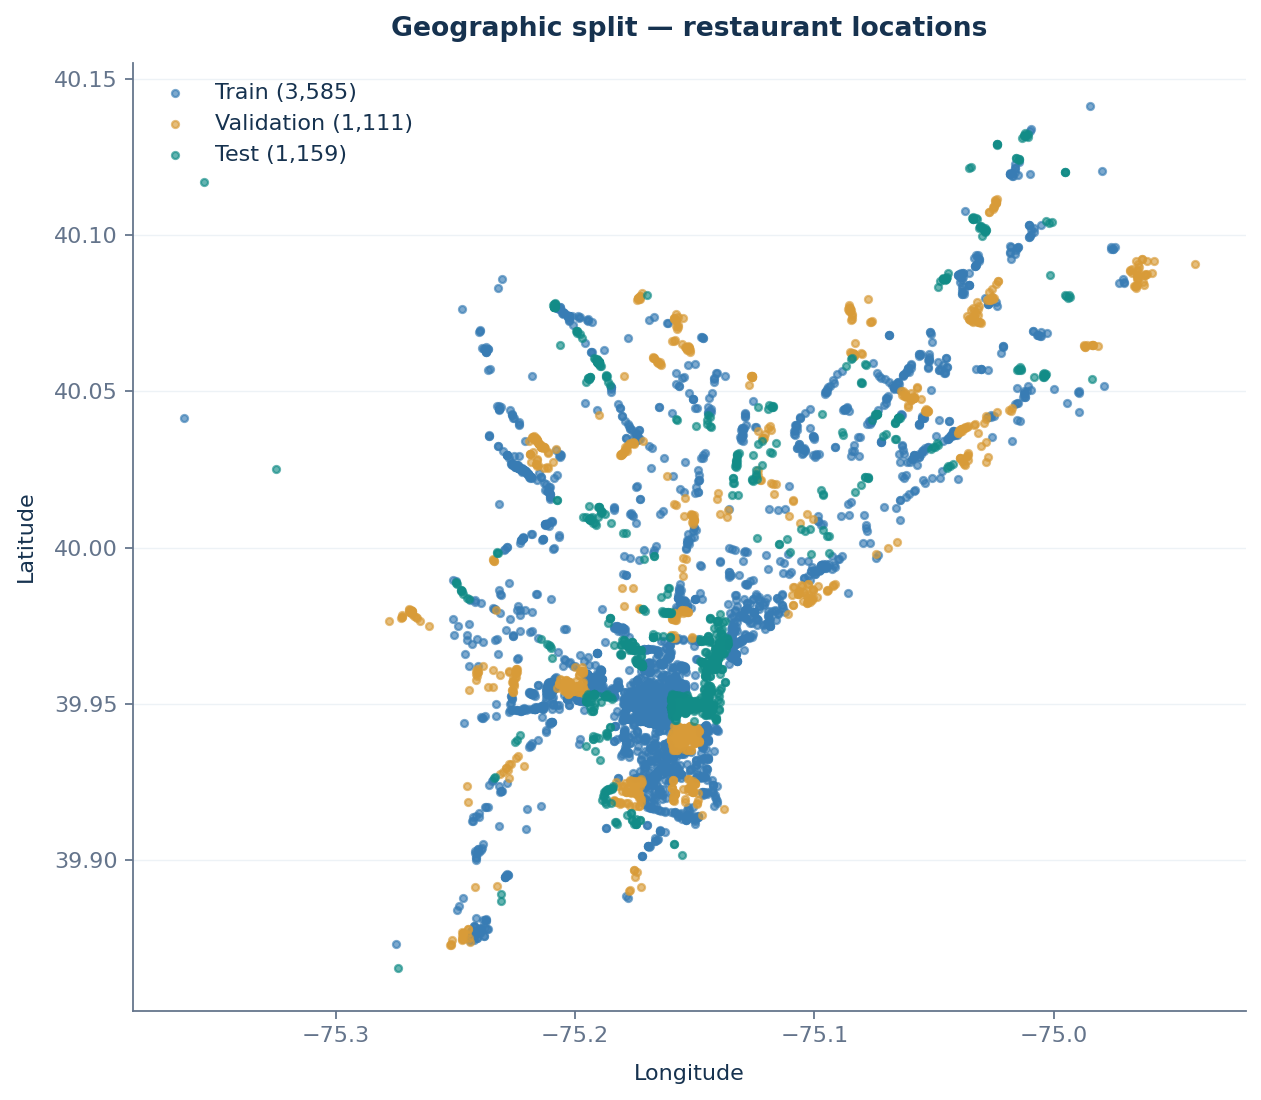

In [10]:
fig, ax = plt.subplots(figsize=(9, 7))
for split, color in SPLIT_COLORS.items():
    mask = split_labels.eq(split)
    ax.scatter(restaurants.loc[mask, 'longitude'], restaurants.loc[mask, 'latitude'],
               s=10, alpha=.65, color=color, label=f'{split.title()} ({int(mask.sum()):,})')
ax.set(title='Geographic split — restaurant locations', xlabel='Longitude', ylabel='Latitude')
ax.set_aspect(1 / np.cos(np.deg2rad(40)))
ax.legend(loc='best')
plt.show()


## 5. Location feature engineering
Distances use a BallTree with the haversine metric: latitude/longitude are converted to radians and radii from km to radians. A competitor is another Philadelphia business tagged `Restaurants`, whether open or closed; open competitors are also counted separately. These counts are a broad competition proxy rather than same-cuisine competition.

Features: competitor counts at 0.5, 1 and 2 km; density per km² at 1 km; open competitors; mean nearby rating; mean/sum nearby cumulative reviews from training reference restaurants; reference-neighbor count; distance to Philadelphia City Hall; latitude/longitude, own rating, open status, price range, category count, and 20 restaurant tags selected from training data only. No own review count, ID or business name enters the predictors.

All neighbor features are restricted to Philadelphia. Counts near the city edge are therefore incomplete for cross-boundary competition.

**Audit correction:** nearby cumulative review sums/means, training-reference neighbor count and the catalog-wide neighboring rating mean are excluded from regression. They remain useful descriptive features. The model uses only location geometry, own snapshot attributes and training-selected category indicators. Own rating is permitted for existing-business snapshot estimates; it is unavailable for a true pre-opening forecast.


In [11]:
def safe_price(attributes):
    value = attributes.get('RestaurantsPriceRange2')
    try:
        price = float(str(value).strip("'\""))
        return price if price in {1, 2, 3, 4} else np.nan
    except (ValueError, TypeError):
        return np.nan

train_reference = restaurants.iloc[train_idx].copy().reset_index(drop=True)
tag_counts_train = Counter(tag for tags in train_reference['category_list'] for tag in tags
                           if tag not in {'Restaurants', 'Food'})
TOP_TAGS = [tag for tag, count in tag_counts_train.most_common(20)]

def engineer_location_features(query, catalog, review_reference, top_tags):
    query = query.reset_index(drop=True)
    catalog = catalog.reset_index(drop=True)
    reference = review_reference.reset_index(drop=True)
    q_coords = np.radians(query[['latitude', 'longitude']].to_numpy(dtype=float))
    catalog_tree = BallTree(np.radians(catalog[['latitude', 'longitude']].to_numpy()), metric='haversine')
    ref_tree = BallTree(np.radians(reference[['latitude', 'longitude']].to_numpy()), metric='haversine')
    result = query[['latitude', 'longitude', 'stars', 'is_open']].copy()
    result['price_range'] = query['attributes'].map(safe_price)
    result['category_count'] = query['category_list'].map(len)
    q_ids = query['business_id'].to_numpy()
    catalog_ids = catalog['business_id'].to_numpy()
    for radius in [.5, 1., 2.]:
        neighbors = catalog_tree.query_radius(q_coords, r=radius / EARTH_RADIUS_KM)
        other_neighbors = [idx[catalog_ids[idx] != q_ids[i]] for i, idx in enumerate(neighbors)]
        suffix = str(radius).replace('.', 'p')
        result[f'competitors_{suffix}km'] = [len(idx) for idx in other_neighbors]
        if radius == 1.:
            result['open_competitors_1km'] = [int(catalog.iloc[idx]['is_open'].eq(1).sum())
                                              for idx in other_neighbors]
            result['nearby_rating_mean_1km'] = [catalog.iloc[idx]['stars'].mean()
                                               for idx in other_neighbors]
    result['competitor_density_1km'] = result['competitors_1p0km'] / np.pi
    ref_ids = reference['business_id'].to_numpy()
    ref_neighbors = ref_tree.query_radius(q_coords, r=1. / EARTH_RADIUS_KM)
    other_ref = [idx[ref_ids[idx] != q_ids[i]] for i, idx in enumerate(ref_neighbors)]
    result['reference_neighbors_1km'] = [len(idx) for idx in other_ref]
    result['nearby_review_mean_1km'] = [reference.iloc[idx]['review_count'].mean() for idx in other_ref]
    result['nearby_review_sum_1km'] = [reference.iloc[idx]['review_count'].sum() for idx in other_ref]
    # Philadelphia City Hall: an approximate centrality reference, not a fitted coordinate.
    center_lat, center_lon = np.radians([39.9526, -75.1636])
    delta_lat, delta_lon = q_coords[:, 0] - center_lat, q_coords[:, 1] - center_lon
    a = np.sin(delta_lat / 2)**2 + np.cos(q_coords[:, 0]) * np.cos(center_lat) * np.sin(delta_lon / 2)**2
    result['distance_city_hall_km'] = 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    for tag in top_tags:
        result[f'tag__{tag}'] = query['category_list'].map(lambda tags: int(tag in tags))
    return result

X = engineer_location_features(restaurants, restaurants, train_reference, TOP_TAGS)
y = restaurants['review_count'].astype(float)
assert 'review_count' not in X and 'business_id' not in X
assert np.isfinite(X.dropna().to_numpy()).all()
display(X.head())


,latitude,longitude,stars,is_open,price_range,category_count,competitors_0p5km,competitors_1p0km,open_competitors_1km,nearby_rating_mean_1km,competitors_2p0km,competitor_density_1km,reference_neighbors_1km,nearby_review_mean_1km,nearby_review_sum_1km,distance_city_hall_km,tag__Nightlife,tag__Bars,tag__Sandwiches,tag__Pizza,tag__American (New),tag__Breakfast & Brunch,tag__American (Traditional),tag__Coffee & Tea,tag__Chinese,tag__Italian,tag__Fast Food,tag__Burgers,tag__Seafood,tag__Cafes,tag__Mexican,tag__Event Planning & Services,tag__Salad,tag__Delis,tag__Specialty Food,tag__Bakeries
0,39.955505,-75.155564,4.0,1.0,1.0,5,265,748,406,3.649733,2302,238.095795,482,207.852697,100185,0.757317,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1
1,39.953949,-75.143226,4.0,1.0,2.0,3,98,348,165,3.622126,1589,110.771840,21,258.095238,5420,1.743101,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,39.943223,-75.162568,4.5,1.0,1.0,2,120,886,418,3.698081,2387,282.022559,539,226.402597,122031,1.046381,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,39.939825,-75.157447,4.0,0.0,2.0,5,195,612,271,3.806373,2290,194.805650,243,185.637860,45110,1.514323,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4,40.022466,-75.218314,3.0,0.0,1.0,4,53,127,61,3.673228,201,40.425356,112,115.142857,12896,9.059947,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


### Feature dictionary and correctness checks
Zero nearby competitors is a valid count. A missing nearby mean indicates no eligible neighbors (or no valid neighbor rating); it is imputed using training rows only. The review reference is fixed to training restaurants. Density divides the 1 km competitor count by π km². The count radii must be monotonic.

The small controlled example checks exclusion by business ID: a different restaurant at the same coordinates must still count as a competitor. It also verifies that a focal restaurant's own reviews do not enter its nearby mean or sum.


In [12]:
descriptions = {
    'latitude': ('degrees', 'Restaurant latitude'),
    'longitude': ('degrees', 'Restaurant longitude'),
    'stars': ('1–5 stars', 'Own snapshot Yelp rating; unavailable for a true cold start'),
    'is_open': ('0 / 1', 'Closed / open at dataset snapshot'),
    'price_range': ('1–4', 'RestaurantsPriceRange2; missing values imputed from training'),
    'category_count': ('tags', 'Number of distinct business category tags'),
    'competitors_0p5km': ('restaurants', 'Other Philadelphia restaurants within 0.5 km'),
    'competitors_1p0km': ('restaurants', 'Other Philadelphia restaurants within 1 km'),
    'competitors_2p0km': ('restaurants', 'Other Philadelphia restaurants within 2 km'),
    'open_competitors_1km': ('restaurants', 'Other open Philadelphia restaurants within 1 km'),
    'nearby_rating_mean_1km': ('stars', 'Mean rating of other catalog restaurants within 1 km'),
    'competitor_density_1km': ('restaurants/km²', 'Competitors within 1 km divided by π'),
    'reference_neighbors_1km': ('restaurants', 'Eligible training-reference neighbors within 1 km'),
    'nearby_review_mean_1km': ('cumulative reviews', 'Mean review count over eligible training-reference neighbors'),
    'nearby_review_sum_1km': ('cumulative reviews', 'Sum of review counts over eligible training-reference neighbors'),
    'distance_city_hall_km': ('km', 'Haversine distance to Philadelphia City Hall')}
feature_dictionary = pd.DataFrame([
    {'feature': col, 'unit': descriptions.get(col, ('0 / 1', 'Training-selected category-tag indicator'))[0],
     'definition': descriptions.get(col, ('0 / 1', 'Training-selected category-tag indicator'))[1]}
    for col in X.columns])
display(feature_dictionary)
display(X.isna().sum().loc[lambda s: s.gt(0)].rename('missing_values').to_frame())
assert (X['competitors_0p5km'] <= X['competitors_1p0km']).all()
assert (X['competitors_1p0km'] <= X['competitors_2p0km']).all()
assert (X['open_competitors_1km'] <= X['competitors_1p0km']).all()
np.testing.assert_allclose(X['competitor_density_1km'], X['competitors_1p0km'] / np.pi)
fixture = pd.DataFrame({
    'business_id': ['A', 'B', 'C'], 'latitude': [39.95, 39.95, 40.10],
    'longitude': [-75.16, -75.16, -75.16], 'stars': [4., 3., 5.], 'is_open': [1, 1, 0],
    'review_count': [10, 20, 30], 'attributes': [{}, {}, {}],
    'category_list': [['Restaurants'], ['Restaurants'], ['Restaurants']]})
fixture_X = engineer_location_features(fixture, fixture, fixture, [])
assert fixture_X.loc[0, 'competitors_1p0km'] == 1  # B counts even though co-located with A.
assert fixture_X.loc[0, 'nearby_review_sum_1km'] == 20  # A's own 10 reviews excluded.
assert fixture_X.loc[0, 'nearby_review_mean_1km'] == 20
assert fixture_X.loc[2, 'competitors_1p0km'] == 0
assert np.isnan(fixture_X.loc[2, 'nearby_review_mean_1km'])
print('Passed: radius monotonicity, density, open counts, co-location, self exclusion, and no-neighbor behavior.')


Passed: radius monotonicity, density, open counts, co-location, self exclusion, and no-neighbor behavior.


,feature,unit,definition
0,latitude,degrees,Restaurant latitude
1,longitude,degrees,Restaurant longitude
2,stars,1–5 stars,Own snapshot Yelp rating; unavailable for a true cold start
3,is_open,0 / 1,Closed / open at dataset snapshot
4,price_range,1–4,RestaurantsPriceRange2; missing values imputed from training
5,category_count,tags,Number of distinct business category tags
6,competitors_0p5km,restaurants,Other Philadelphia restaurants within 0.5 km
7,competitors_1p0km,restaurants,Other Philadelphia restaurants within 1 km
8,open_competitors_1km,restaurants,Other open Philadelphia restaurants within 1 km
9,nearby_rating_mean_1km,stars,Mean rating of other catalog restaurants within 1 km


,missing_values
price_range,914
nearby_rating_mean_1km,8
nearby_review_mean_1km,97


Passed: validation/test-target perturbation does not change features.


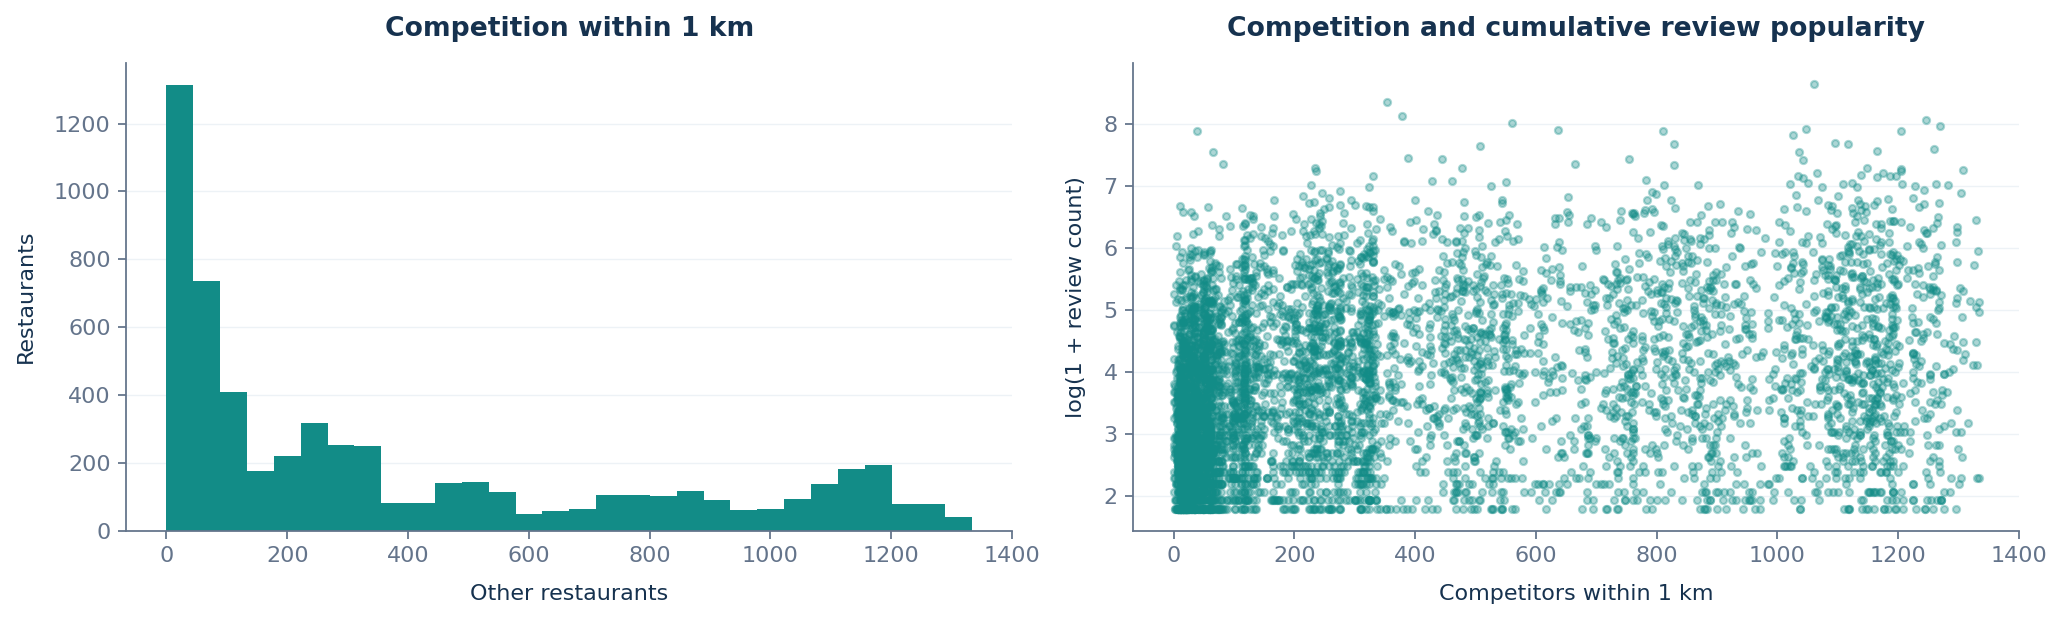

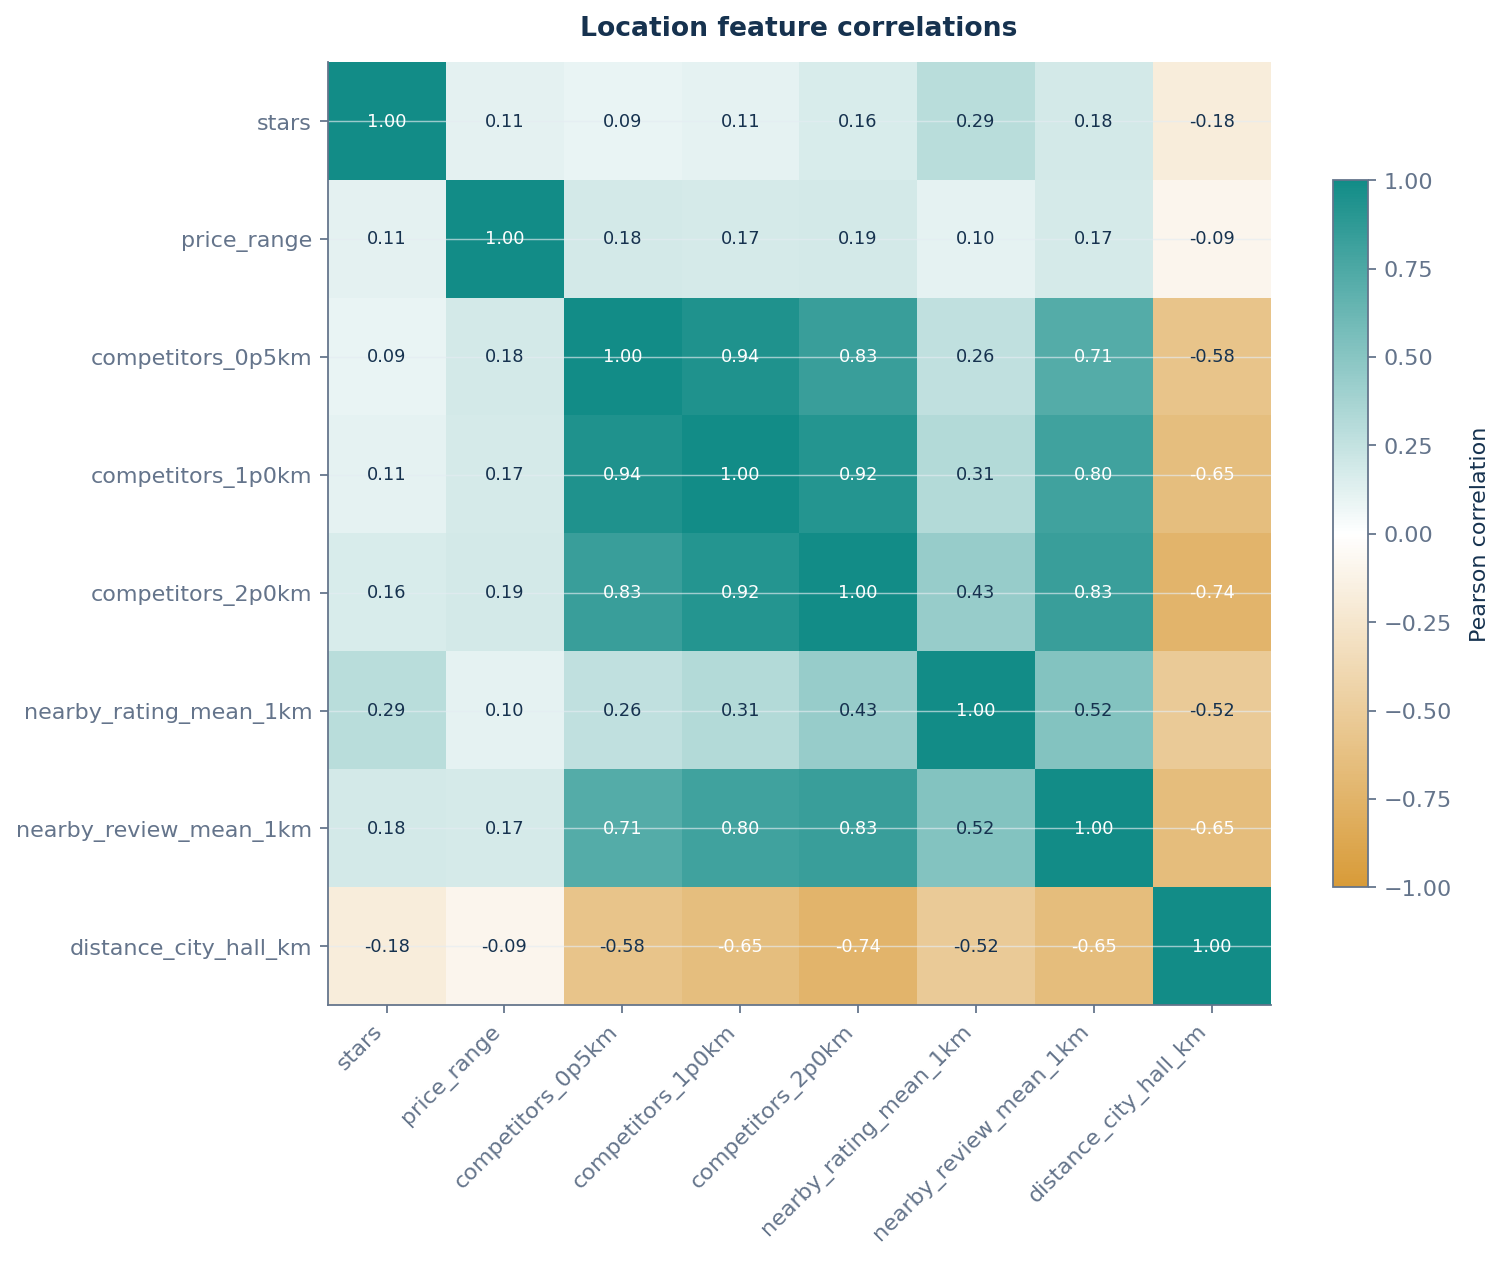

In [13]:
# A held-out target perturbation must not change any predictors.
changed = restaurants.copy()
heldout_idx = np.concatenate([val_idx, test_idx])
changed.loc[heldout_idx, 'review_count'] = changed.loc[heldout_idx, 'review_count'] + 99999
check_X = engineer_location_features(changed, changed, train_reference, TOP_TAGS)
pd.testing.assert_frame_equal(X, check_X)
print('Passed: validation/test-target perturbation does not change features.')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(X['competitors_1p0km'], bins=30, color=THEME['teal'])
axes[0].set(title='Competition within 1 km', xlabel='Other restaurants', ylabel='Restaurants')
axes[1].scatter(X['competitors_1p0km'], np.log1p(y), s=10, alpha=.35, color=THEME['teal'])
axes[1].set(title='Competition and cumulative review popularity', xlabel='Competitors within 1 km',
            ylabel='log(1 + review count)')
plt.tight_layout(); plt.show()
correlation_columns = ['stars', 'price_range', 'competitors_0p5km', 'competitors_1p0km',
                       'competitors_2p0km', 'nearby_rating_mean_1km',
                       'nearby_review_mean_1km', 'distance_city_hall_km']
correlation = X[correlation_columns].corr()
fig, ax = plt.subplots(figsize=(10, 8))
diverging = LinearSegmentedColormap.from_list('philly_correlation',
                                             [THEME['gold'], '#FFFFFF', THEME['teal']])
heat = ax.imshow(correlation, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_columns)), correlation_columns, rotation=45, ha='right')
ax.set_yticks(range(len(correlation_columns)), correlation_columns)
for row in range(len(correlation_columns)):
    for col in range(len(correlation_columns)):
        val = correlation.iloc[row, col]
        ax.text(col, row, f'{val:.2f}', ha='center', va='center',
                color='white' if abs(val) > .6 else THEME['navy'], fontsize=8)
ax.set_title('Location feature correlations')
ax.grid(False)
fig.colorbar(heat, ax=ax, label='Pearson correlation', shrink=.75)
plt.show()


## 6. Regression audit, regularization and spatial cross-validation
The original candidates are rerun on training and validation data to measure their generalization gaps. A large train/validation gap on log-scale MAE or R² indicates possible overfitting; a gap alone is not proof because geographic target distributions differ.

The revised Random Forest candidates have capped depth and larger leaves; Gradient Boosting uses shallow trees, smaller learning rates and larger leaves. For each family, three-fold spatial CV on training blocks selects the candidate with the lowest mean MAE in original review units. A standard Linear Regression and median baseline remain comparators. Each CV fold selects its own top category vocabulary and fits its own imputer/scaler. The model family is then selected by validation MAE. No test scores guide these choices.

The `log1p` target transform and non-negative clipping are retained. The fitted models estimate existing-business cumulative review popularity, not revenue or future popularity. Training-reference labels are not predictors.


Selected by validation MAE: Random Forest
Training-CV selected parameters: {'n_estimators': 150, 'max_depth': 6, 'min_samples_leaf': 20, 'max_features': 0.7}


,model,split,MAE,RMSE,R2,log_MAE,log_R2
0,Median baseline,train,107.059,277.828,-0.094,1.124,-0.004
1,Median baseline,validation,65.541,155.701,-0.050,1.036,-0.046
2,Linear Regression,train,93.922,248.052,0.128,0.899,0.313
3,Linear Regression,validation,64.379,144.352,0.097,0.914,0.089
4,Random Forest,train,60.108,203.853,0.411,0.460,0.807
5,Random Forest,validation,57.323,141.369,0.134,0.844,0.234
6,Gradient Boosting,train,86.163,236.816,0.205,0.800,0.455
7,Gradient Boosting,validation,57.711,142.214,0.124,0.841,0.243


,model,candidate,CV_MAE,CV_MAE_std,CV_RMSE,train_log_MAE,validation_log_MAE
0,Gradient Boosting,0,100.475,21.165,267.806,0.957,0.984
1,Gradient Boosting,1,99.285,20.937,266.150,0.920,0.964
2,Gradient Boosting,2,98.369,20.885,264.715,0.894,0.947
3,Linear Regression,0,96.480,18.194,249.496,0.910,0.940
4,Median baseline,0,107.252,21.706,275.698,1.123,1.128
5,Random Forest,0,98.953,20.943,264.740,0.864,0.962
6,Random Forest,1,99.145,20.593,265.198,0.862,0.967
7,Random Forest,2,99.156,20.420,264.914,0.881,0.968


,MAE,RMSE,R2
model,,,
Random Forest,58.535,144.921,0.090
Gradient Boosting,58.626,145.789,0.079
Linear Regression,62.551,145.269,0.086
Median baseline,65.541,155.701,-0.050


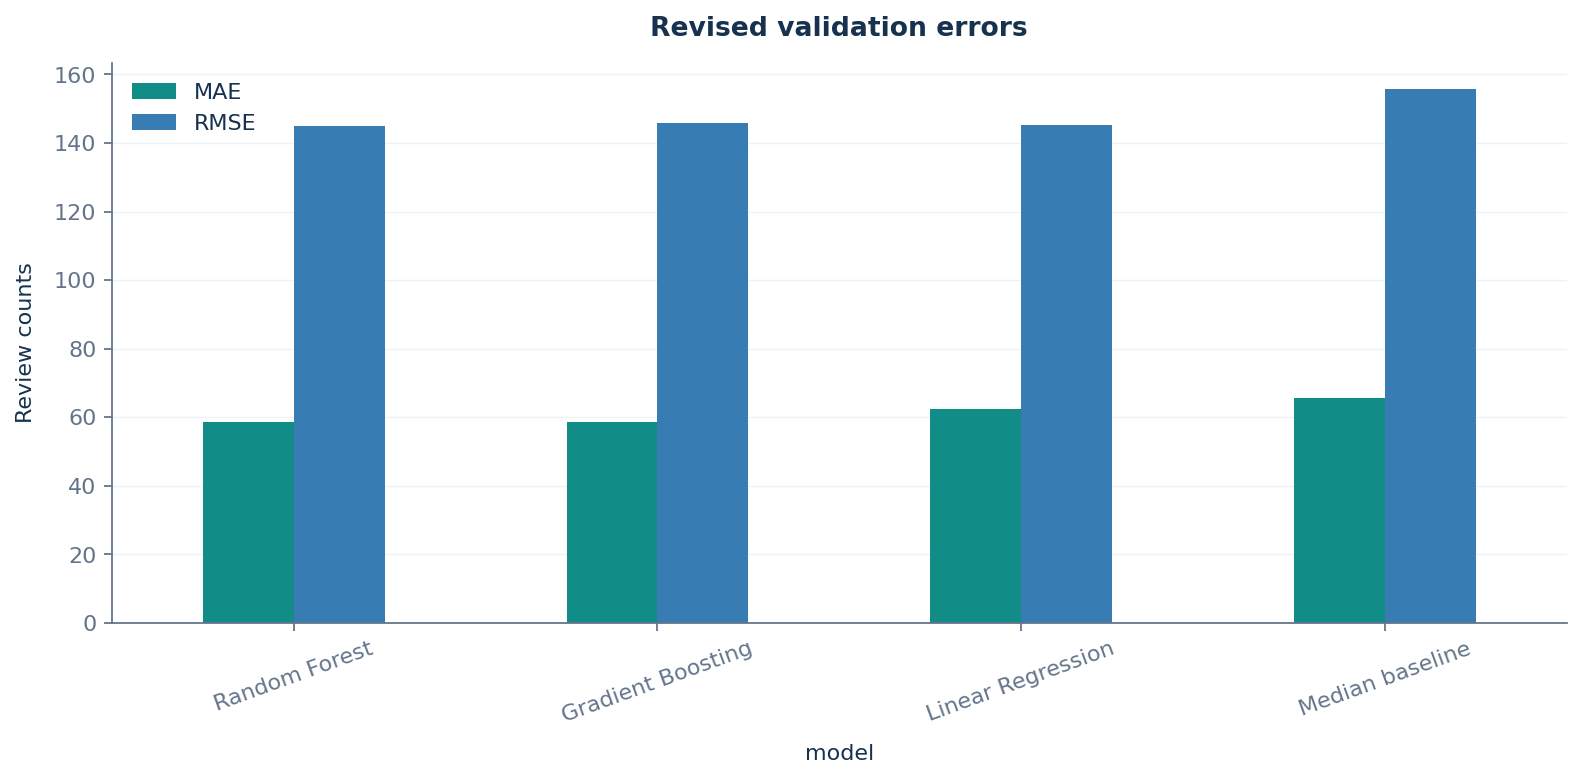

In [14]:
def metrics(actual, prediction):
    return {'MAE': float(mean_absolute_error(actual, prediction)),
            'RMSE': float(np.sqrt(mean_squared_error(actual, prediction))),
            'R2': float(r2_score(actual, prediction))}

def predict_counts(model, features):
    return np.maximum(model.predict(features), 0)

def make_regression_pipeline(estimator):
    return TransformedTargetRegressor(
        regressor=Pipeline([('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                            ('scale', StandardScaler()), ('regressor', estimator)]),
        func=np.log1p, inverse_func=np.expm1)

def log_metrics(actual, prediction):
    return {'log_MAE': float(mean_absolute_error(np.log1p(actual), np.log1p(prediction))),
            'log_R2': float(r2_score(np.log1p(actual), np.log1p(prediction)))}

original_estimators = {
    'Median baseline': DummyRegressor(strategy='median'),
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                           max_features=.8, n_jobs=-1, random_state=SEED),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=.05,
                                                   max_depth=3, random_state=SEED)}
original_rows = []
for name, estimator in original_estimators.items():
    original_model = make_regression_pipeline(estimator)
    original_model.fit(X.iloc[train_idx], y.iloc[train_idx])
    for split_name, indices in [('train', train_idx), ('validation', val_idx)]:
        prediction = predict_counts(original_model, X.iloc[indices])
        original_rows.append({'model': name, 'split': split_name,
                              **metrics(y.iloc[indices], prediction),
                              **log_metrics(y.iloc[indices], prediction)})
original_audit = pd.DataFrame(original_rows)
display(original_audit.round(3))

EXCLUDED_MODEL_FEATURES = ['nearby_review_mean_1km', 'nearby_review_sum_1km',
                          'reference_neighbors_1km', 'nearby_rating_mean_1km']
BASE_MODEL_FEATURES = [col for col in X.columns if not col.startswith('tag__')
                       and col not in EXCLUDED_MODEL_FEATURES]

def learn_category_tags(indices, frame=restaurants):
    counts = Counter(tag for tags in frame.iloc[indices]['category_list'] for tag in tags
                     if tag not in {'Restaurants', 'Food'})
    return [tag for tag, count in counts.most_common(20)]

def build_model_matrix(feature_frame, restaurant_frame, vocabulary):
    result = feature_frame[BASE_MODEL_FEATURES].copy()
    for tag in vocabulary:
        result[f'tag__{tag}'] = restaurant_frame['category_list'].map(lambda tags: int(tag in tags)).to_numpy()
    return result

MODEL_TAGS = learn_category_tags(train_idx)
X_model = build_model_matrix(X, restaurants, MODEL_TAGS)
feature_dictionary['used_in_regression'] = feature_dictionary['feature'].isin(X_model.columns)
assert not set(EXCLUDED_MODEL_FEATURES) & set(X_model.columns)

candidate_specs = {
    'Median baseline': [{'strategy': 'median'}],
    'Linear Regression': [{}],
    'Random Forest': [
        {'n_estimators': 150, 'max_depth': 6, 'min_samples_leaf': 20, 'max_features': .7},
        {'n_estimators': 150, 'max_depth': 8, 'min_samples_leaf': 30, 'max_features': .7},
        {'n_estimators': 150, 'max_depth': 10, 'min_samples_leaf': 40, 'max_features': .7}],
    'Gradient Boosting': [
        {'n_estimators': 150, 'learning_rate': .03, 'max_depth': 1, 'min_samples_leaf': 30},
        {'n_estimators': 100, 'learning_rate': .03, 'max_depth': 2, 'min_samples_leaf': 30},
        {'n_estimators': 150, 'learning_rate': .03, 'max_depth': 2, 'min_samples_leaf': 50}]}

def instantiate(family, parameters):
    if family == 'Median baseline':
        return DummyRegressor(**parameters)
    if family == 'Linear Regression':
        return LinearRegression(**parameters)
    if family == 'Random Forest':
        return RandomForestRegressor(**parameters, n_jobs=-1, random_state=SEED)
    return GradientBoostingRegressor(**parameters, random_state=SEED)

cv_splits = list(GroupKFold(n_splits=3).split(restaurants.iloc[train_idx], groups=groups.iloc[train_idx]))
cv_rows = []
for family, specifications in candidate_specs.items():
    for candidate_id, parameters in enumerate(specifications):
        for fold, (fold_train_local, fold_validation_local) in enumerate(cv_splits, 1):
            fold_train, fold_validation = train_idx[fold_train_local], train_idx[fold_validation_local]
            assert not (set(groups.iloc[fold_train]) & set(groups.iloc[fold_validation]))
            fold_tags = learn_category_tags(fold_train)
            fold_X = build_model_matrix(X, restaurants, fold_tags)
            model = make_regression_pipeline(instantiate(family, parameters))
            model.fit(fold_X.iloc[fold_train], y.iloc[fold_train])
            fit_prediction = predict_counts(model, fold_X.iloc[fold_train])
            holdout_prediction = predict_counts(model, fold_X.iloc[fold_validation])
            cv_rows.append({'model': family, 'candidate': candidate_id, 'fold': fold,
                            'parameters': json.dumps(parameters, sort_keys=True),
                            'train_log_MAE': log_metrics(y.iloc[fold_train], fit_prediction)['log_MAE'],
                            'validation_log_MAE': log_metrics(y.iloc[fold_validation], holdout_prediction)['log_MAE'],
                            **metrics(y.iloc[fold_validation], holdout_prediction)})
cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby(['model', 'candidate'], as_index=False).agg(
    CV_MAE=('MAE', 'mean'), CV_MAE_std=('MAE', 'std'), CV_RMSE=('RMSE', 'mean'),
    train_log_MAE=('train_log_MAE', 'mean'), validation_log_MAE=('validation_log_MAE', 'mean'))
display(cv_summary.round(3))

models, selected_parameters, validation_rows = {}, {}, []
for family in candidate_specs:
    chosen = int(cv_summary[cv_summary['model'].eq(family)].sort_values('CV_MAE').iloc[0]['candidate'])
    parameters = candidate_specs[family][chosen]
    selected_parameters[family] = parameters
    model = make_regression_pipeline(instantiate(family, parameters))
    model.fit(X_model.iloc[train_idx], y.iloc[train_idx])
    models[family] = model
    prediction = predict_counts(model, X_model.iloc[val_idx])
    validation_rows.append({'model': family, **metrics(y.iloc[val_idx], prediction)})
validation_results = pd.DataFrame(validation_rows).set_index('model').sort_values('MAE')
display(validation_results.round(3))
best_name = validation_results.drop(index='Median baseline')['MAE'].idxmin()
best_model = models[best_name]
print('Selected by validation MAE:', best_name)
print('Training-CV selected parameters:', selected_parameters[best_name])
validation_results[['MAE', 'RMSE']].plot.bar(rot=20,
    title='Revised validation errors', color=[THEME['teal'], THEME['blue']])
plt.ylabel('Review counts'); plt.show()


### Target-free predictors and leakage assertions
The prediction matrix excludes all review-count-based neighbor summaries and the target itself. Altering **every** restaurant's review count must leave this matrix unchanged. Altering held-out ratings must also leave training rows unchanged, because catalog-wide neighbor ratings are excluded. IDs are unique and spatial groups are disjoint.

Catalog geometry includes held-out locations by design: it is a known-business-catalog snapshot, not a strict unknown-location or pre-opening forecast. Fitted imputation statistics are checked against training-only medians. Category vocabularies are relearned separately inside every CV fold.


In [15]:
changed_all = restaurants.copy()
changed_all['review_count'] = np.arange(len(changed_all)) * 17 + 99999
changed_reference = changed_all.iloc[train_idx].reset_index(drop=True)
changed_features = engineer_location_features(changed_all, changed_all, changed_reference, TOP_TAGS)
changed_matrix = build_model_matrix(changed_features, changed_all, MODEL_TAGS)
pd.testing.assert_frame_equal(X_model, changed_matrix)

changed_ratings = restaurants.copy()
changed_ratings.loc[np.concatenate([val_idx, test_idx]), 'stars'] = 1
changed_rating_features = engineer_location_features(changed_ratings, changed_ratings, train_reference, TOP_TAGS)
changed_rating_matrix = build_model_matrix(changed_rating_features, changed_ratings, MODEL_TAGS)
pd.testing.assert_frame_equal(X_model.iloc[train_idx], changed_rating_matrix.iloc[train_idx])

expected_medians = X_model.iloc[train_idx].median().fillna(0).to_numpy()
for family, model in models.items():
    imputer = model.regressor_.named_steps['imputer']
    np.testing.assert_allclose(imputer.statistics_, expected_medians)
    assert model.regressor_.named_steps['scale'].n_samples_seen_ == len(train_idx)

leakage_audit = pd.DataFrame([
    {'check': 'Unique business IDs', 'passed': bool(restaurants['business_id'].is_unique)},
    {'check': 'Disjoint train/validation/test spatial groups', 'passed': not bool(
        (set(groups.iloc[train_idx]) & set(groups.iloc[val_idx])) or
        (set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])) or
        (set(groups.iloc[val_idx]) & set(groups.iloc[test_idx])))},
    {'check': 'Target and neighbor review aggregates excluded from predictors', 'passed':
        not bool(set(EXCLUDED_MODEL_FEATURES + ['review_count']) & set(X_model.columns))},
    {'check': 'All-target perturbation leaves predictor matrix unchanged', 'passed': True},
    {'check': 'Held-out rating perturbation leaves training predictors unchanged', 'passed': True},
    {'check': 'Imputer and scaler fitted only on training rows', 'passed': True},
    {'check': 'Category vocabulary learned from training or fold-training rows only', 'passed': True},
    {'check': 'Spatial CV folds have no overlapping geographic blocks', 'passed': True}])
assert leakage_audit['passed'].all()
display(leakage_audit)
print('All implemented leakage checks passed. This does not establish temporal forecasting validity.')


All implemented leakage checks passed. This does not establish temporal forecasting validity.


,check,passed
0,Unique business IDs,True
1,Disjoint train/validation/test spatial groups,True
2,Target and neighbor review aggregates excluded from predictors,True
3,All-target perturbation leaves predictor matrix unchanged,True
4,Held-out rating perturbation leaves training predictors unchanged,True
5,Imputer and scaler fitted only on training rows,True
6,Category vocabulary learned from training or fold-training rows only,True
7,Spatial CV folds have no overlapping geographic blocks,True


### Before/after generalization diagnostics
Train and validation log-scale metrics are compared on the same rows as the original run. A smaller training advantage indicates less fitting to training-specific patterns. Regularization can lower training scores while improving generalization; it does not guarantee higher test scores. Target-free feature changes and regularization are applied together, so their separate contributions cannot be identified from this comparison.


Random Forest log-MAE gap: 0.384 -> -0.007.
Gradient Boosting log-MAE gap: 0.042 -> -0.034.


,model,split,MAE,RMSE,R2,log_MAE,log_R2,version
0,Median baseline,train,107.059,277.828,-0.094,1.124,-0.004,original
1,Median baseline,validation,65.541,155.701,-0.050,1.036,-0.046,original
2,Linear Regression,train,93.922,248.052,0.128,0.899,0.313,original
3,Linear Regression,validation,64.379,144.352,0.097,0.914,0.089,original
4,Random Forest,train,60.108,203.853,0.411,0.460,0.807,original
5,Random Forest,validation,57.323,141.369,0.134,0.844,0.234,original
6,Gradient Boosting,train,86.163,236.816,0.205,0.800,0.455,original
7,Gradient Boosting,validation,57.711,142.214,0.124,0.841,0.243,original
8,Median baseline,train,107.059,277.828,-0.094,1.124,-0.004,revised
9,Median baseline,validation,65.541,155.701,-0.050,1.036,-0.046,revised


split                       train  validation  validation_minus_train_log_MAE
version  model                                                               
original Gradient Boosting  0.800       0.841                           0.042
         Linear Regression  0.899       0.914                           0.015
         Median baseline    1.124       1.036                          -0.088
         Random Forest      0.460       0.844                           0.384
revised  Gradient Boosting  0.903       0.869                          -0.034
         Linear Regression  0.917       0.914                          -0.003
         Median baseline    1.124       1.036                          -0.088
         Random Forest      0.877       0.870                          -0.007

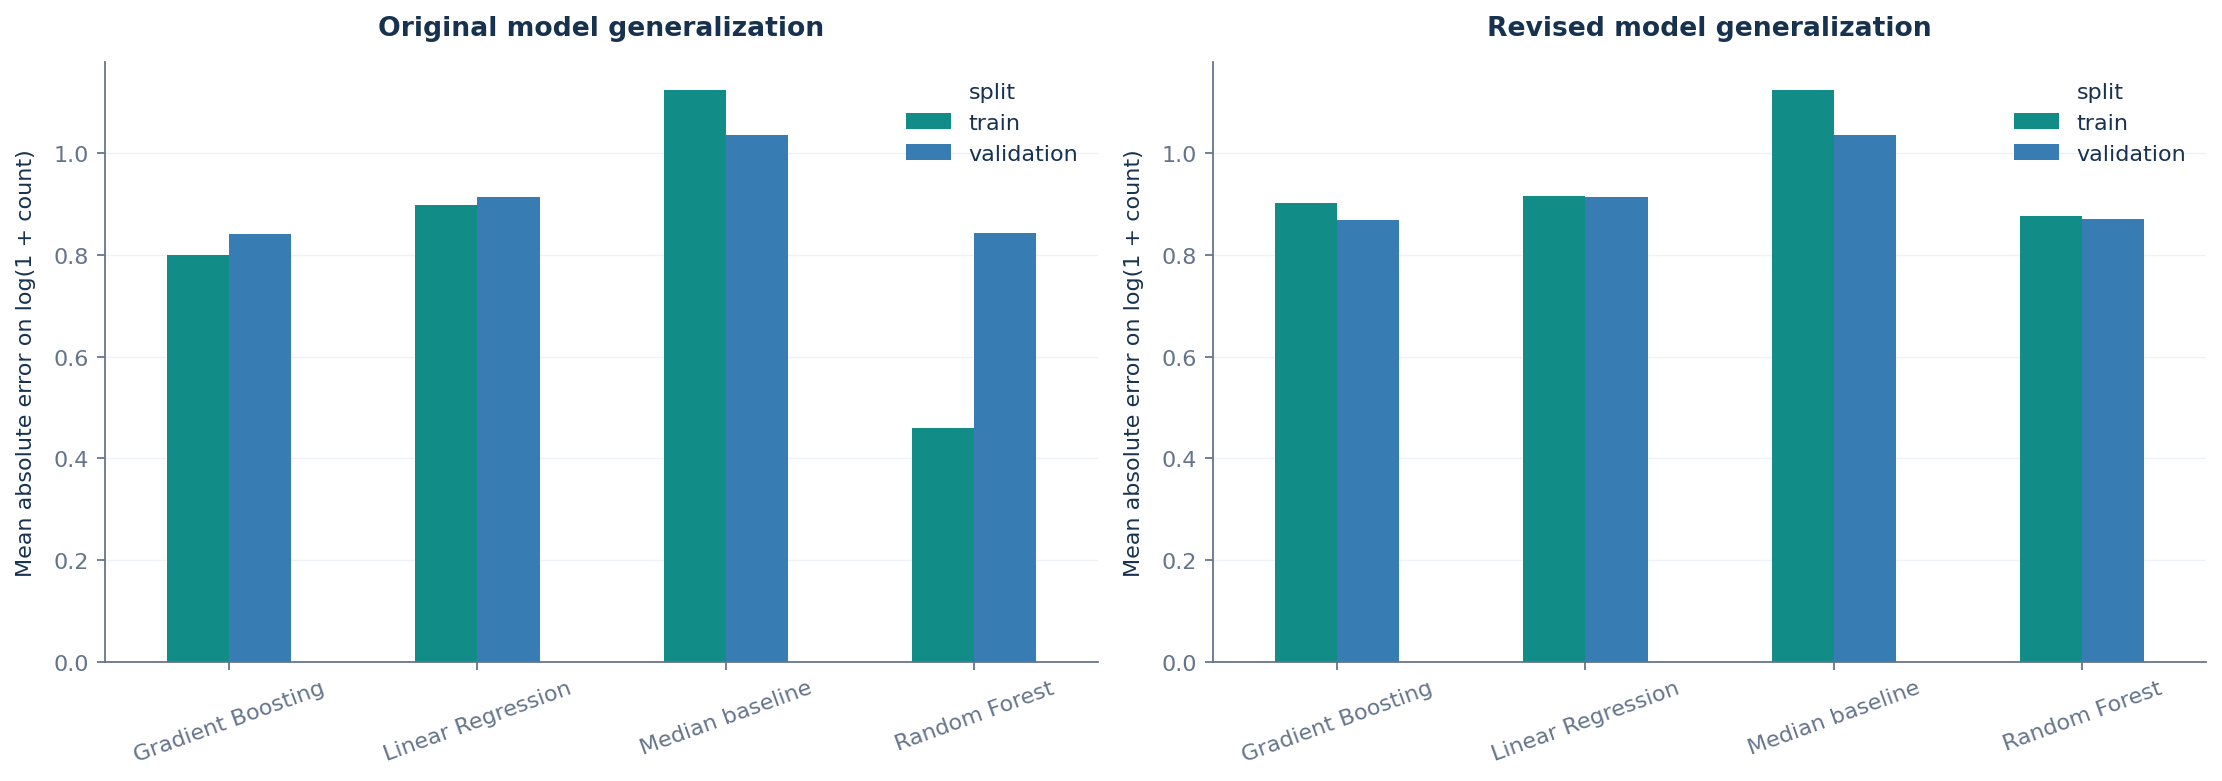

In [16]:
diagnostic_rows = []
for family, model in models.items():
    for split_name, indices in [('train', train_idx), ('validation', val_idx)]:
        prediction = predict_counts(model, X_model.iloc[indices])
        diagnostic_rows.append({'version': 'revised', 'model': family, 'split': split_name,
                                **metrics(y.iloc[indices], prediction),
                                **log_metrics(y.iloc[indices], prediction)})
generalization = pd.concat([original_audit.assign(version='original'), pd.DataFrame(diagnostic_rows)], ignore_index=True)
display(generalization.round(3))
gap_table = generalization.pivot(index=['version', 'model'], columns='split', values='log_MAE')
gap_table['validation_minus_train_log_MAE'] = gap_table['validation'] - gap_table['train']
display(gap_table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, version in zip(axes, ['original', 'revised']):
    data = generalization[generalization['version'].eq(version)].pivot(index='model', columns='split', values='log_MAE')
    data[['train', 'validation']].plot.bar(ax=axis, color=[THEME['teal'], THEME['blue']], rot=20)
    axis.set(title=f'{version.title()} model generalization', ylabel='Mean absolute error on log(1 + count)', xlabel='')
plt.show()
for family in ['Random Forest', 'Gradient Boosting']:
    before = float(gap_table.loc[('original', family), 'validation_minus_train_log_MAE'])
    after = float(gap_table.loc[('revised', family), 'validation_minus_train_log_MAE'])
    print(f'{family} log-MAE gap: {before:.3f} -> {after:.3f}.')


## 7. Descriptive re-evaluation and residual analysis
The model was selected using validation only. All revised fixed candidates are evaluated on the original test set for completeness, using MAE, RMSE and R² in review-count units. Because the test set was seen in earlier notebook versions, these are **descriptive re-evaluation results**, not an untouched final benchmark.

Permutation importance uses validation data and the same clipped predictions as scoring. No parameters are changed after the test metrics are computed. Original-unit and log-scale train/validation gaps are reported to avoid overlooking tail errors or differences in target distributions.


,MAE,RMSE,R2
model,,,
Median baseline,99.424,239.636,-0.101
Linear Regression,90.336,217.174,0.096
Random Forest,91.184,221.609,0.059
Gradient Boosting,91.157,223.481,0.043


,business_id,name,stars,review_count,prediction,residual_actual_minus_prediction,absolute_error
1262,ctHjyadbDQAtUFfkcAFEHw,Zahav,4.5,3065,167.384654,2897.615346,2897.615346
636,S8ZFYEgMejpChID8tzKo9A,Amada,4.0,2109,102.739035,2006.260965,2006.260965
3834,i_FWONQD1ZBqrNE2b-M5Ug,Talula's Garden,4.5,1927,176.002405,1750.997595,1750.997595
3485,6_T2xzR74JqGCTPefAD8Tw,Morimoto,4.5,1914,193.871565,1720.128435,1720.128435
1223,-mIlmp5l4hKlp1tvHRdvTg,Sonny's Famous Steaks,4.0,1697,93.124422,1603.875578,1603.875578
5032,nIAbuktMEzVjT4P9pG89rQ,Buddakan,4.0,1561,145.454109,1415.545891,1415.545891
5708,K7KHmHzxNwzqiijSJeKe_A,Cafe La Maude,4.5,1485,83.627312,1401.372688,1401.372688
5437,qISf5ojuYbD9h71NumGUQA,Han Dynasty,4.0,1474,106.046376,1367.953624,1367.953624
566,cXSyVvOr9YRN9diDkaWs0Q,Honey's Sit-N-Eat,4.0,1396,73.980851,1322.019149,1322.019149
343,d_tRshM-w6S4QxE4VVi8tQ,Jones,3.5,1141,62.527606,1078.472394,1078.472394


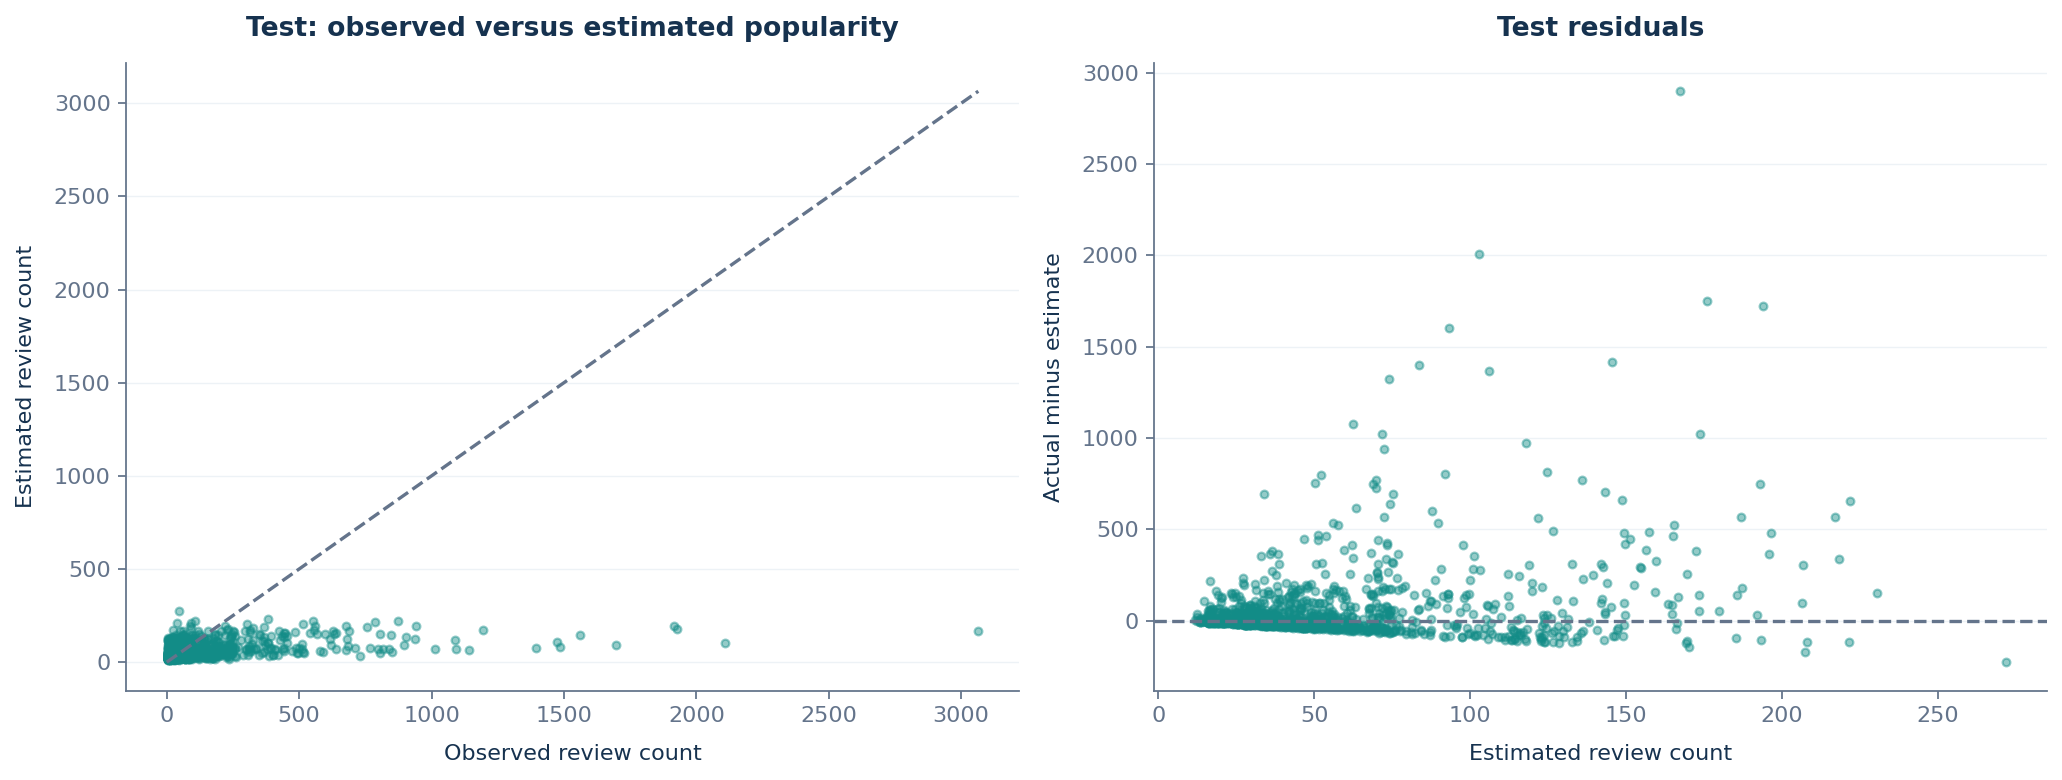

,feature,MAE_increase,std
3,is_open,4.820947,0.389639
2,stars,1.909363,0.242968
6,competitors_0p5km,1.182146,0.172684
7,competitors_1p0km,0.662541,0.166073
5,category_count,0.520689,0.124719
4,price_range,0.331853,0.049796
9,competitors_2p0km,0.278567,0.040510
13,tag__Bars,0.229957,0.066611
10,competitor_density_1km,0.212856,0.131108
8,open_competitors_1km,0.130306,0.033611


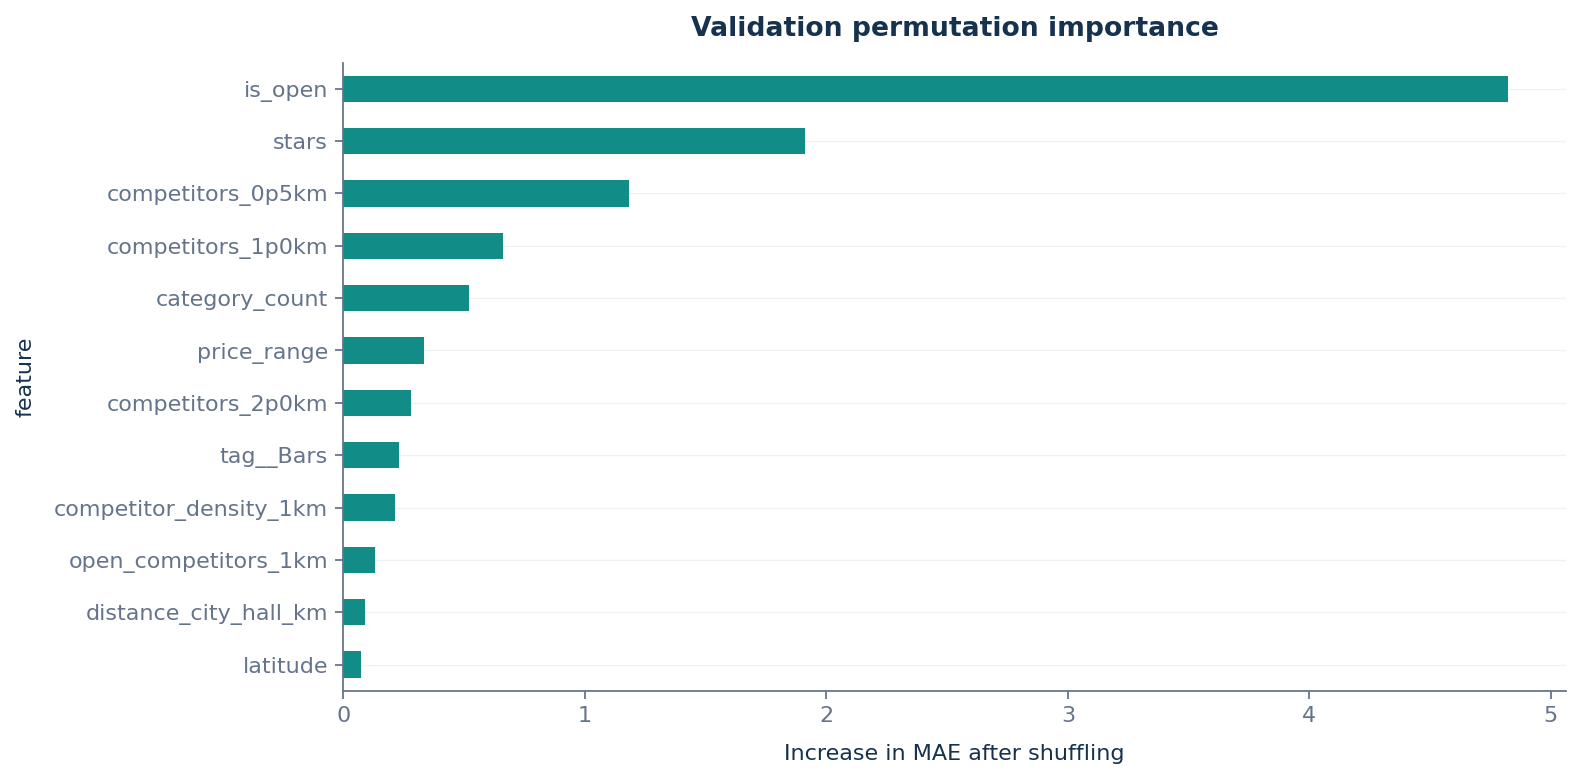

In [17]:
test_prediction = predict_counts(best_model, X_model.iloc[test_idx])
baseline_prediction = predict_counts(models['Median baseline'], X_model.iloc[test_idx])
test_results = pd.DataFrame([
    {'model': name, **metrics(y.iloc[test_idx], predict_counts(model, X_model.iloc[test_idx]))}
    for name, model in models.items()
]).set_index('model')
# Reporting all fixed candidates on test does not change the selected model.
display(test_results.round(3))

test_detail = restaurants.iloc[test_idx][['business_id', 'name', 'stars', 'review_count']].copy()
test_detail['prediction'] = test_prediction
test_detail['residual_actual_minus_prediction'] = test_detail['review_count'] - test_prediction
test_detail['absolute_error'] = np.abs(test_detail['residual_actual_minus_prediction'])
display(test_detail.nlargest(10, 'absolute_error'))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y.iloc[test_idx], test_prediction, alpha=.45, s=12, color=THEME['teal'])
limit = max(float(y.iloc[test_idx].max()), float(test_prediction.max()))
axes[0].plot([0, limit], [0, limit], '--', color=THEME['muted'])
axes[0].set(title='Test: observed versus estimated popularity', xlabel='Observed review count', ylabel='Estimated review count')
axes[1].scatter(test_prediction, y.iloc[test_idx] - test_prediction, alpha=.45, s=12, color=THEME['teal'])
axes[1].axhline(0, color=THEME['muted'], linestyle='--')
axes[1].set(title='Test residuals', xlabel='Estimated review count', ylabel='Actual minus estimate')
plt.tight_layout(); plt.show()

# Interpretation on validation data; the test set does not drive model changes.
importance = permutation_importance(best_model, X_model.iloc[val_idx], y.iloc[val_idx],
                                    scoring=lambda model, features, actual: -mean_absolute_error(actual, predict_counts(model, features)), n_repeats=3,
                                    random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'feature': X_model.columns, 'MAE_increase': importance.importances_mean,
                                  'std': importance.importances_std}).sort_values('MAE_increase', ascending=False)
display(importance_table.head(15))
importance_table.head(12).sort_values('MAE_increase').plot.barh(x='feature', y='MAE_increase', legend=False, color=THEME['teal'])
plt.title('Validation permutation importance'); plt.xlabel('Increase in MAE after shuffling')
plt.tight_layout(); plt.show()


Selection is unchanged: Random Forest (chosen before viewing test metrics).


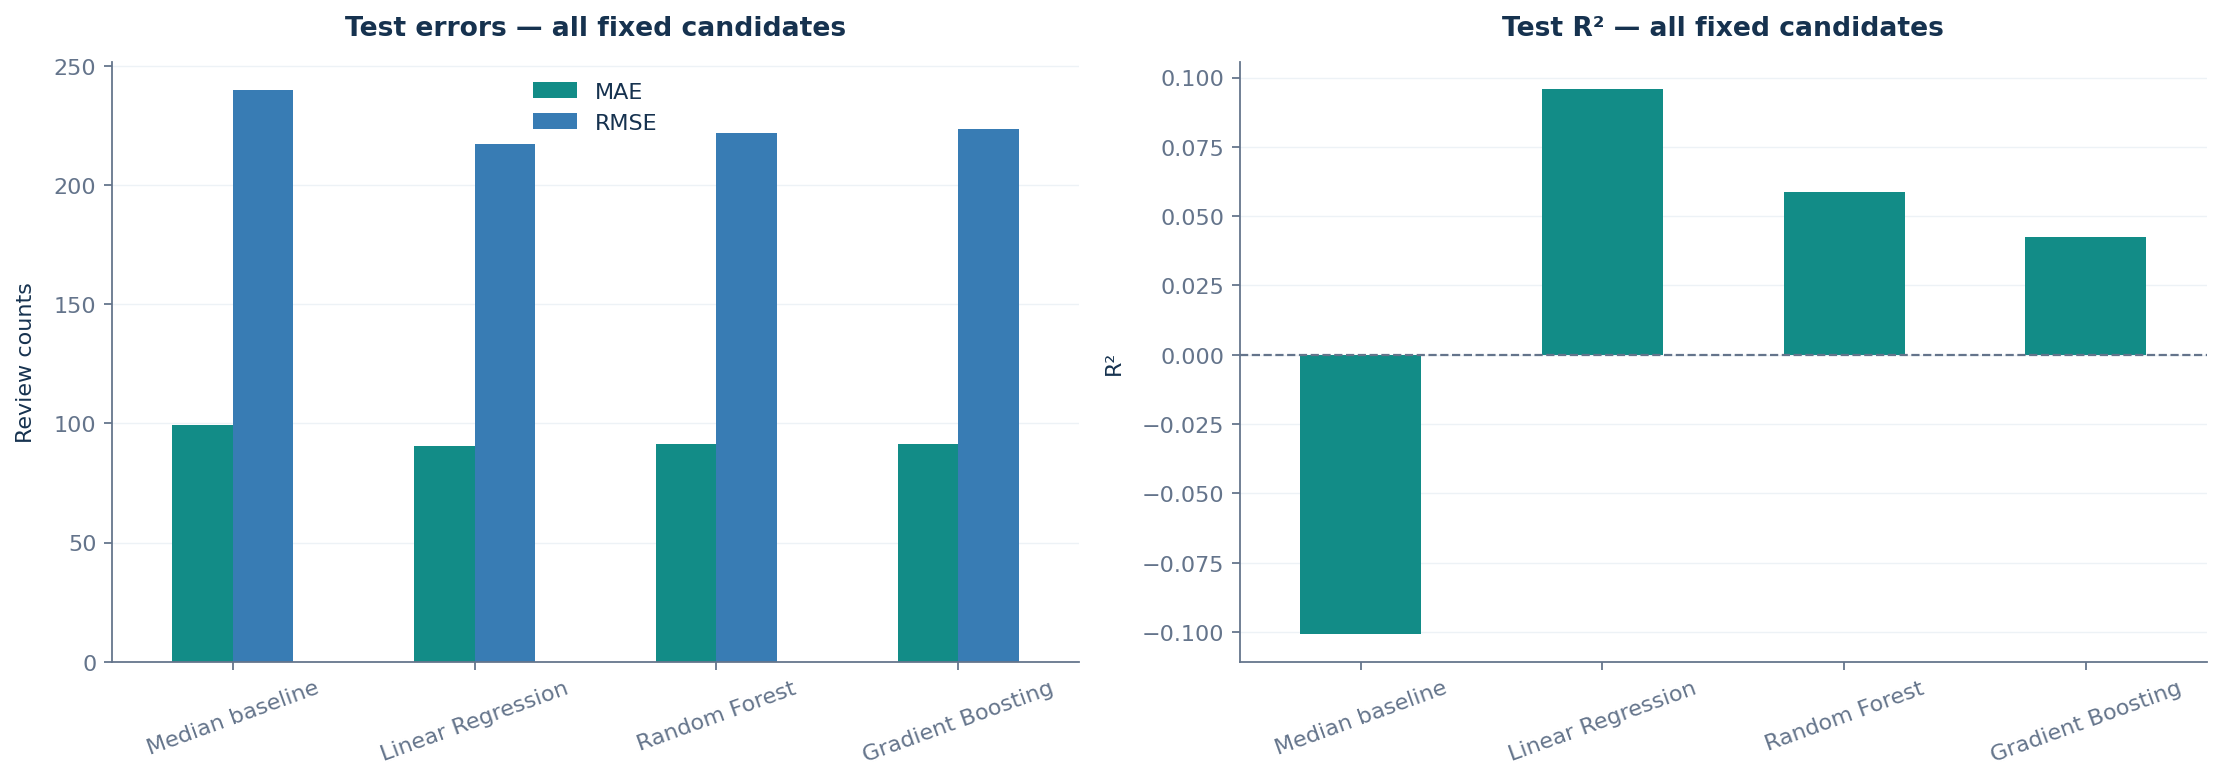

,restaurants,MAE,median_error
popularity_band,,,
0–20,398,27.94,21.19
21–100,451,29.21,22.60
101–500,255,147.02,129.51
>500,55,798.14,653.10


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ordered_models = ['Median baseline', 'Linear Regression', 'Random Forest', 'Gradient Boosting']
test_results.loc[ordered_models, ['MAE', 'RMSE']].plot.bar(
    ax=axes[0], color=[THEME['teal'], THEME['blue']], rot=20)
axes[0].set(title='Test errors — all fixed candidates', ylabel='Review counts', xlabel='')
test_results.loc[ordered_models, 'R2'].plot.bar(ax=axes[1], color=THEME['teal'], rot=20)
axes[1].axhline(0, linestyle='--', color=THEME['muted'], linewidth=1)
axes[1].set(title='Test R² — all fixed candidates', ylabel='R²', xlabel='')
plt.show()
print('Selection is unchanged:', best_name, '(chosen before viewing test metrics).')

# Absolute-error summaries expose uneven performance across target popularity levels.
test_detail['popularity_band'] = pd.cut(test_detail['review_count'],
    bins=[-1, 20, 100, 500, np.inf], labels=['0–20', '21–100', '101–500', '>500'])
error_by_band = test_detail.groupby('popularity_band', observed=False).agg(
    restaurants=('business_id', 'size'), MAE=('absolute_error', 'mean'),
    median_error=('absolute_error', 'median'))
display(error_by_band.round(2))
error_by_band.to_csv(OUTPUT_DIR / 'test_error_by_popularity.csv')


In [19]:
selected_metrics = test_results.loc[best_name]
baseline_mae = test_results.loc['Median baseline', 'MAE']
improvement = 100 * (baseline_mae - selected_metrics['MAE']) / baseline_mae if baseline_mae else np.nan
print(f'{best_name}: test MAE={selected_metrics["MAE"]:.2f}, '
      f'RMSE={selected_metrics["RMSE"]:.2f}, R²={selected_metrics["R2"]:.3f}.')
print(f'Test MAE improvement versus median baseline: {improvement:.1f}%.')
print('Strongest validation features:', ', '.join(importance_table.head(5)['feature']))
print('These are snapshot associations, not evidence that location causes popularity or revenue.')


Random Forest: test MAE=91.18, RMSE=221.61, R²=0.059.
Test MAE improvement versus median baseline: 8.3%.
Strongest validation features: is_open, stars, competitors_0p5km, competitors_1p0km, category_count
These are snapshot associations, not evidence that location causes popularity or revenue.


## 8. Export data, trained model and interactive map
The model bundle preserves its pipeline, feature order, category vocabulary and reference/candidate catalogs. The location table supports collaboration through `business_id`. Training predictions are in-sample; validation guides selection; test predictions use the reused original test split. Preserve these labels when sharing results.

The HTML map uses Leaflet and OpenStreetMap; map tiles and library scripts need internet access in the browser. Marker popups display ratings, competition, observed/estimated review counts and split labels.


In [20]:
location_table = pd.concat([restaurants[['business_id', 'name', 'address', 'city', 'state',
                                          'postal_code', 'categories', 'review_count']].reset_index(drop=True), X], axis=1)
location_table['split'] = split_labels.to_numpy()
location_table['estimated_review_count'] = predict_counts(best_model, X_model)
location_table['prediction_context'] = np.where(location_table['split'].eq('train'),
                                               'in-sample', 'held-out')
location_table.to_csv(OUTPUT_DIR / 'philadelphia_location_features.csv', index=False)
clean_export = business.drop(columns=['category_list']).copy()
clean_export['attributes'] = clean_export['attributes'].map(json.dumps)
if 'hours' in clean_export:
    clean_export['hours'] = clean_export['hours'].map(json.dumps)
clean_export.to_csv(OUTPUT_DIR / 'philadelphia_business_clean.csv', index=False)
validation_results.to_csv(OUTPUT_DIR / 'validation_metrics.csv')
test_results.to_csv(OUTPUT_DIR / 'test_metrics.csv')
test_detail.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
importance_table.to_csv(OUTPUT_DIR / 'validation_feature_importance.csv', index=False)
joblib.dump({'model': best_model, 'model_name': best_name, 'feature_columns': list(X_model.columns),
             'category_tags': MODEL_TAGS, 'train_reference': train_reference,
             'restaurant_catalog': restaurants, 'seed': SEED, 'sklearn_version': sklearn.__version__,
             'target': 'cumulative review_count; not revenue'}, OUTPUT_DIR / 'member1_model.joblib')
metadata = {'city': 'Philadelphia', 'state': 'PA', 'audit': audit, 'selected_model': best_name,
            'target': 'review_count', 'test_metrics': selected_metrics.to_dict(),
            'review_file_used': False, 'split_counts': split_labels.value_counts().to_dict(),
            'feature_columns': list(X_model.columns), 'sklearn_version': sklearn.__version__}
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')

markers = []
for _, row in location_table.iterrows():
    popup = (f'<b>{html.escape(str(row["name"]))}</b><br>'
             f'Rating: {row["stars"]}<br>Reviews: {row["review_count"]:,}<br>'
             f'Estimated reviews: {row["estimated_review_count"]:.0f}<br>'
             f'Competitors (1 km): {row["competitors_1p0km"]}<br>'
             f'Split: {row["split"]} ({row["prediction_context"]})')
    markers.append({'lat': row['latitude'], 'lon': row['longitude'], 'popup': popup,
                    'split': row['split']})
map_template = """<!doctype html><html><head><meta charset="utf-8"><title>Philadelphia restaurant locations</title>
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css">
<style>body{margin:0;font-family:Arial}header{padding:14px;background:#102a43;color:white}#map{height:80vh}</style>
</head><body><header><b>Philadelphia · Restaurant location intelligence</b><br>
Cumulative Yelp popularity, not revenue · blue: train; gold: validation; teal: test</header><div id="map"></div>
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script><script>
const map=L.map('map').setView([39.9526,-75.1636],12);
L.tileLayer('https://{s}.tile.openstreetmap.org/{z}/{x}/{y}.png',
{attribution:'© OpenStreetMap contributors',maxZoom:19}).addTo(map);
const data=__MARKERS__; const colors={train:'#387CB4',validation:'#D89B38',test:'#128C87'};
data.forEach(d=>L.circleMarker([d.lat,d.lon],{radius:4,color:colors[d.split],weight:1,fillOpacity:.65})
.addTo(map).bindPopup(d.popup));
</script></body></html>"""
# Avoid HTML script termination through a business name.
map_html = map_template.replace('__MARKERS__', json.dumps(markers).replace('</', r'<\/'))
map_path = OUTPUT_DIR / 'philadelphia_restaurant_map.html'
map_path.write_text(map_html, encoding='utf-8')
try:
    from IPython.display import HTML, display
    display(HTML('<iframe srcdoc="' + html.escape(map_html, quote=True) +
                 '" width="100%" height="650" style="border:0"></iframe>'))
except ImportError:
    print('Open the HTML map in a browser:', map_path)
print('Saved data, metrics, model and map to', OUTPUT_DIR.resolve())

postal_summary.to_csv(OUTPUT_DIR / 'philadelphia_postal_summary.csv')
feature_dictionary.to_csv(OUTPUT_DIR / 'feature_dictionary.csv', index=False)

cv_results.to_csv(OUTPUT_DIR / 'spatial_cv_results.csv', index=False)
generalization.to_csv(OUTPUT_DIR / 'generalization_diagnostics.csv', index=False)
original_audit.to_csv(OUTPUT_DIR / 'original_model_audit.csv', index=False)
leakage_audit.to_csv(OUTPUT_DIR / 'leakage_audit.csv', index=False)
(OUTPUT_DIR / 'audit_summary.json').write_text(json.dumps({
    'excluded_regression_features': EXCLUDED_MODEL_FEATURES,
    'selected_parameters': selected_parameters,
    'cv_folds': 3, 'selection_rule': 'train-block CV MAE per family, then validation MAE',
    'test_status': 'reused original test set; descriptive re-evaluation only',
    'catalog_assumption': 'full restaurant geometry known; no catalog review targets used in model features',
    'leakage_checks_passed': bool(leakage_audit['passed'].all())}, indent=2), encoding='utf-8')

regression_inputs = pd.concat([restaurants[['business_id', 'review_count']].reset_index(drop=True), X_model], axis=1)
regression_inputs['split'] = split_labels.to_numpy()
regression_inputs.to_csv(OUTPUT_DIR / 'philadelphia_regression_inputs.csv', index=False)


Open the HTML map in a browser: member1_philadelphia_outputs/philadelphia_restaurant_map.html
Saved data, metrics, model and map to /workspace/scratch/65af53800b61/member1_philadelphia_outputs


## 9. Generate the Streamlit location analysis page
Run the next cell to write the app. From a terminal in the output folder:

```bash
python -m pip install -r requirements.txt
python -m streamlit run streamlit_location.py
```

The page provides a map, category/status/split filters, observed and estimated popularity, competition summaries, an individual-restaurant inspector, and CSV download. Its estimates concern existing catalog restaurants; it does not claim to forecast a new restaurant's revenue. The selected pipeline scores saved feature rows, preserving feature order.


In [21]:
APP_SOURCE = r"""
from pathlib import Path
import json
import joblib
import pandas as pd
import numpy as np
import streamlit as st
import pydeck as pdk

ROOT = Path(__file__).resolve().parent
st.set_page_config(page_title="Philadelphia Location Intelligence", page_icon="📍", layout="wide")
@st.cache_resource
def load_bundle():
    return joblib.load(ROOT / "member1_model.joblib")
@st.cache_data
def load_data():
    return pd.read_csv(ROOT / "philadelphia_location_features.csv")
if not (ROOT / "philadelphia_location_features.csv").exists():
    st.error("Run the Member 1 notebook first to create the data and model.")
    st.stop()
bundle, data = load_bundle(), load_data()
st.title("Philadelphia · Location Intelligence")
st.caption("Yelp cumulative review popularity · Philadelphia, Pennsylvania · Member 1")
st.info("Estimated review counts are snapshot popularity proxies, not revenue or forecasts. Training rows are in-sample; the validation split selects the model, and the original test set is reused for descriptive re-evaluation.")
all_tags = sorted({t.strip() for text in data["categories"].fillna("") for t in text.split(",") if t.strip()})
tag = st.sidebar.selectbox("Restaurant category", ["All"] + all_tags)
status = st.sidebar.selectbox("Status", ["All", "Open", "Closed"])
splits = st.sidebar.multiselect("Data split", ["train", "validation", "test"], default=["train", "validation", "test"])
filtered = data[data["split"].isin(splits)].copy()
if tag != "All":
    filtered = filtered[filtered["categories"].fillna("").map(lambda v: tag in {t.strip() for t in v.split(",")})]
if status != "All":
    filtered = filtered[filtered["is_open"].eq(1 if status == "Open" else 0)]
if filtered.empty:
    st.warning("No restaurants match the filters.")
    st.stop()
a,b,c,d = st.columns(4)
a.metric("Restaurants", f"{len(filtered):,}")
b.metric("Mean rating", f"{filtered['stars'].mean():.2f}")
c.metric("Median reviews", f"{filtered['review_count'].median():.0f}")
d.metric("Median competitors / 1 km", f"{filtered['competitors_1p0km'].median():.0f}")
metric = st.selectbox("Map color", ["competitors_1p0km", "review_count", "estimated_review_count", "stars"])
scaled = np.log1p(filtered[metric].fillna(0).clip(lower=0))
scaled = (scaled-scaled.min()) / max(float(scaled.max()-scaled.min()), 1e-9)
filtered["color"] = [[int(18+4*v), int(140-90*v), int(135-56*v), 190] for v in scaled]
layer = pdk.Layer("ScatterplotLayer", data=filtered, get_position="[longitude, latitude]",
                  get_fill_color="color", get_radius=45, pickable=True)
st.pydeck_chart(pdk.Deck(layers=[layer], initial_view_state=pdk.ViewState(latitude=39.9526, longitude=-75.1636, zoom=11),
                         tooltip={"text":"{name}\nStars: {stars}\nReviews: {review_count}\nEstimate: {estimated_review_count}\nCompetitors (1 km): {competitors_1p0km}\nSplit: {split}"}))
st.subheader("Restaurant inspector")
options = filtered["business_id"].tolist()
labels = dict(zip(filtered["business_id"], filtered["name"].astype(str) + " — " + filtered["address"].astype(str)))
chosen = st.selectbox("Select restaurant", options, format_func=lambda key: labels[key])
row = filtered.loc[filtered["business_id"].eq(chosen)].iloc[0]
features = filtered.loc[filtered["business_id"].eq(chosen), bundle["feature_columns"]]
estimate = max(float(bundle["model"].predict(features)[0]), 0)
st.write({"Restaurant": row["name"], "Address": row["address"], "Model": bundle["model_name"],
          "Estimated cumulative reviews": round(estimate), "Observed reviews": int(row["review_count"]),
          "Competitors within 1 km": int(row["competitors_1p0km"]), "Split": row["split"],
          "Prediction context": row["prediction_context"]})
st.subheader("Filtered restaurant table")
st.dataframe(filtered.drop(columns="color"), use_container_width=True)
st.download_button("Download filtered CSV", filtered.drop(columns="color").to_csv(index=False).encode("utf-8"),
                   "philadelphia_restaurants.csv", "text/csv")
with st.expander("Held-out metrics and definitions"):
    st.dataframe(pd.read_csv(ROOT / "test_metrics.csv"), use_container_width=True)
    st.write("Competitors include open and closed Philadelphia restaurants; the separate open-competitor feature counts open businesses only. Nearby review aggregates use only training reference restaurants and exclude the focal business; they are EDA features and are excluded from the regression model. City-edge counts exclude suburban restaurants.")
"""
(OUTPUT_DIR / 'streamlit_location.py').write_text(APP_SOURCE, encoding='utf-8')
(OUTPUT_DIR / 'requirements.txt').write_text(
    f'pandas>=2.0\nnumpy>=1.24\nmatplotlib>=3.7\nscikit-learn=={sklearn.__version__}\njoblib>=1.3\nstreamlit>=1.30\npydeck>=0.8\nkagglehub>=0.3\n', encoding='utf-8')
print('Streamlit page generated:', OUTPUT_DIR / 'streamlit_location.py')


Streamlit page generated: member1_philadelphia_outputs/streamlit_location.py


## 10. Member 1 deliverables and presentation notes
Running this notebook creates:

| Deliverable | File |
|---|---|
| Leakage audit, spatial CV and generalization diagnostics | `leakage_audit.csv`, `spatial_cv_results.csv`, `generalization_diagnostics.csv` |
| Original model audit | `original_model_audit.csv` |
| Consistently styled PNG/SVG plots | `figures/` |
| Postal-code EDA and feature dictionary | `philadelphia_postal_summary.csv`, `feature_dictionary.csv` |
| Rejected-row cleaning audit | `rejected_philadelphia_rows.csv` |
| Cleaned Philadelphia business data | `philadelphia_business_clean.csv` |
| Audited 32-feature regression inputs and row labels | `philadelphia_regression_inputs.csv` |
| Restaurant location features, split and predictions | `philadelphia_location_features.csv` |
| Trained selected regression pipeline and catalogs | `member1_model.joblib` |
| Validation and final test metrics | `validation_metrics.csv`, `test_metrics.csv` |
| Error by restaurant popularity band | `test_error_by_popularity.csv` |
| Final test predictions and feature interpretation | `test_predictions.csv`, `validation_feature_importance.csv` |
| Interactive location map | `philadelphia_restaurant_map.html` |
| Streamlit location page and dependencies | `streamlit_location.py`, `requirements.txt` |
| Run metadata and cleaning audit | `run_summary.json` |

**Presentation outline:** explain the Philadelphia filter and cleaning audit; show category/rating/location charts; define haversine competition and training-only review features; compare the three required regressors on validation; report the selected model's final MAE/RMSE/R² against the median baseline; demonstrate the map; explain limitations.

**Limitations:** review count depends on age, Yelp coverage and customer behavior, not just location. Opening dates and revenue are unavailable. Ratings and neighbor counts are contemporaneous snapshot information, so this is not a future forecast or a cold-start model. Closed businesses may have accumulated reviews before closure. Spatial blocks reduce but do not eliminate geographic dependence. Mean nearby cumulative review count is not a rate; recent review activity needs the omitted review JSON and a defined time window. Feature importance describes predictive association and can be unstable for correlated features.

**Team handoff:** join other members' outputs by `business_id`, retaining city/state and split labels. No sentiment analysis, topic modeling, or clustering is performed here.

**Audit limitations:** the reused test set is not a new independent benchmark. The full catalog is used only for target-free geometry; if catalog coverage changes, competition counts and model performance can change. Temporal leakage cannot be assessed without dated feature snapshots and review histories, so no forecasting claim is made.


In [22]:
# Optional: package the generated companion artifacts for your submission/team.
import shutil
archive_path = shutil.make_archive('Member1_Philadelphia_Artifacts', 'zip', root_dir=OUTPUT_DIR)
print('Companion artifact archive:', archive_path)


Companion artifact archive: /workspace/scratch/65af53800b61/Member1_Philadelphia_Artifacts.zip
